<a href="https://colab.research.google.com/github/MeenakshiRajpurohit/CMPE-297-Natural-Language-Processing/blob/main/Week4_HW_RNN_LSTM_Recipe_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color: blue">Week 4 Homework: Deep Dive into RNN and LSTM</span>
## Character-level recipe generator trained on my own corpus

**Student:** Meenakshi Rajpurohit

**What I built.** I built a character-level LSTM language model (from the Week 4 class demo code) that writes **vegetarian home-cooking recipes**. It is trained on a corpus of **62 recipes I wrote myself** (`my_recipe_corpus.txt`, about 42,500 characters). I also compare SimpleRNN, GRU and LSTM variants (optional 1) and a word-level LSTM (optional 2). Finally, I use the **OpenAI API** to draw the generated dish and to blind-grade the samples.


## 1. Understanding key concepts

### 1A. Recurrent Neural Networks (RNN) for text generation
A language model assigns a probability to a sequence by predicting **one token at a time**:

$$p(x_1,\dots,x_T)=\prod_{t=1}^{T} p(x_t \mid x_1,\dots,x_{t-1})$$

An RNN reads the sequence step by step and stores everything it has seen in a **hidden state** $h_t$, which acts as its memory. The **same weights are reused at every time step**:

$$h_t=\tanh(W_{xh}\,x_t+W_{hh}\,h_{t-1}+b_h),\qquad \hat y_t=\mathrm{softmax}(W_{hy}\,h_t+b_y)$$

* **Training (teacher forcing):** the input is the text, and the target is the same text shifted by one position. The loss is the cross-entropy between $\hat y_t$ and the true next character.
* **Generation (autoregressive):** sample a character from $\hat y_t$, feed it back in as the next input, carry the hidden state forward, and repeat. A **temperature** $\tau$ rescales the logits ($z/\tau$): a low $\tau$ gives safe, repetitive text, and a high $\tau$ gives creative but error-prone text.

### 1B. Why plain RNNs struggle: vanishing and exploding gradients
Back-propagation through time multiplies one Jacobian per time step:

$$\frac{\partial h_T}{\partial h_t}=\prod_{k=t+1}^{T}\mathrm{diag}\!\left(1-h_k^2\right)W_{hh}$$

If the factors are smaller than 1, the product **shrinks exponentially**. Characters far in the past then get almost no learning signal (*vanishing gradient*), so a plain RNN cannot learn long-range dependencies. In a recipe, for example, the title *"Mango Lassi"* should still influence the ingredient list about 100 characters later. If the factors are larger than 1, the gradient *explodes*, which is usually handled with gradient clipping.

### 1C. Long Short-Term Memory (LSTM)
An LSTM adds a separate **cell state** $c_t$ and three learned **gates**:

$$\begin{aligned}
f_t&=\sigma(W_f[h_{t-1},x_t]+b_f) &&\text{forget gate: how much old memory to keep}\\
i_t&=\sigma(W_i[h_{t-1},x_t]+b_i) &&\text{input gate: how much new info to write}\\
\tilde c_t&=\tanh(W_c[h_{t-1},x_t]+b_c) &&\text{candidate memory}\\
o_t&=\sigma(W_o[h_{t-1},x_t]+b_o) &&\text{output gate: how much memory to expose}\\
c_t&=f_t\odot c_{t-1}+i_t\odot\tilde c_t &&\text{additive update}\\
h_t&=o_t\odot\tanh(c_t)
\end{aligned}$$

The key is the **additive** cell update. Along the cell path, $\partial c_t/\partial c_{t-1}=\mathrm{diag}(f_t)$, with no squashing non-linearity and no repeated multiplication by $W_{hh}$. When the network learns $f_t\approx 1$, information and gradients can flow across many steps (the "constant error carousel"). Because there are 4 gate blocks, an LSTM has **4×** the weights of a SimpleRNN with the same width: $4(EH+H^2+H)$ parameters. A **GRU** is a lighter variant with two gates (update and reset) and no separate cell state, so it has 3× the weights.

The small experiment below makes the vanishing-gradient effect visible. For a random 100-step input, it measures how strongly the *last* hidden state depends on each *earlier* input ($\lVert\partial h_T/\partial x_t\rVert$).

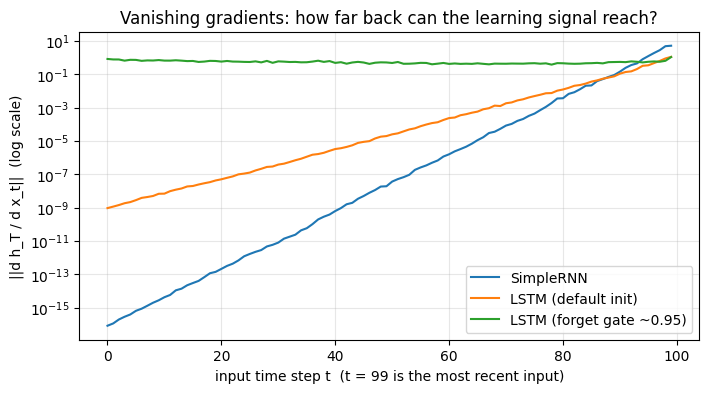

SimpleRNN                  gradient from t=99: 5.10e+00 | from t=0: 8.30e-17 | ratio t0/t99: 1.6e-17
LSTM (default init)        gradient from t=99: 1.10e+00 | from t=0: 9.36e-10 | ratio t0/t99: 8.5e-10
LSTM (forget gate ~0.95)   gradient from t=99: 1.07e+00 | from t=0: 8.19e-01 | ratio t0/t99: 7.7e-01


In [1]:
# Vanishing-gradient demo: how much does the LAST hidden state depend on each earlier input?
# We measure || d(sum h_T) / d x_t || for every time step t of a random 100-step sequence.
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)
T, E, H = 100, 64, 128
x_demo = tf.random.normal((1, T, E))

def grad_wrt_inputs(layer):
    with tf.GradientTape() as tape:
        tape.watch(x_demo)
        h_T = layer(x_demo)                  # final hidden state only
        s = tf.reduce_sum(h_T)
    g = tape.gradient(s, x_demo)[0]          # shape (T, E)
    return tf.norm(g, axis=-1).numpy()       # one number per time step

rnn_layer = tf.keras.layers.SimpleRNN(H)
lstm_layer = tf.keras.layers.LSTM(H)

lstm_open = tf.keras.layers.LSTM(H)          # same LSTM, but with the forget gate pushed open
lstm_open.build((1, T, E))
bias = lstm_open.cell.bias.numpy()
bias[H:2 * H] = 3.0                          # Keras gate order is [input, forget, candidate, output]
lstm_open.cell.bias.assign(bias)             # forget gate f = sigmoid(3) ~ 0.95 -> "keep the memory"

curves = {"SimpleRNN": grad_wrt_inputs(rnn_layer),
          "LSTM (default init)": grad_wrt_inputs(lstm_layer),
          "LSTM (forget gate ~0.95)": grad_wrt_inputs(lstm_open)}

plt.figure(figsize=(8, 4))
for name, c in curves.items():
    plt.semilogy(range(T), c, label=name)
plt.xlabel("input time step t  (t = 99 is the most recent input)")
plt.ylabel("||d h_T / d x_t||  (log scale)")
plt.title("Vanishing gradients: how far back can the learning signal reach?")
plt.legend(); plt.grid(alpha=0.3); plt.show()

for name, c in curves.items():
    print(f"{name:26s} gradient from t=99: {c[-1]:.2e} | from t=0: {c[0]:.2e} | ratio t0/t99: {c[0] / c[-1]:.1e}")

**What the plot shows.** For the **SimpleRNN**, the gradient from the first input is roughly $10^{-17}$ times the gradient from the last input. In practice it learns nothing from characters 100 steps back. The **LSTM with its forget gate open** keeps the gradient at about the same size across all 100 steps, because the cell state is a nearly un-squashed additive path. A freshly initialized LSTM sits in between. During training, the LSTM can *learn* to open its forget gate whenever it needs to remember something, such as which dish it is writing. This is exactly the mechanism that lets LSTMs overcome the vanishing-gradient problem.

## 2. Code-structure analysis of the class demo

| Class demo section | What the code does | Key code | What I changed for this homework |
|---|---|---|---|
| **1.2 Setup** | Imports TensorFlow and reads the corpus (a cocktail PDF via `PyPDF2`) | `PdfReader(...).extract_text()` | My corpus is my own **plain-text file of 62 recipes** (embedded in the notebook). Added a GPU check and a fixed random seed. |
| **1.3 Text → numbers** | Builds the character vocabulary. `StringLookup` maps char → ID, `invert=True` maps ID → char, and `reduce_join` turns characters back into a string | `ids_from_chars`, `chars_from_ids`, `text_from_ids` | Same |
| **1.4.1 Training examples** | Stream of IDs → chunks of `seq_length+1` → `split_input_target` (input = chars 0…99, target = chars 1…100) | `from_tensor_slices`, `.batch()`, `.map()` | Added a **recipe-level train/validation split** (6 recipes held out) so generalization can be measured |
| **1.4.2 Batches** | Shuffle, batch, prefetch | `.shuffle().batch().prefetch()` | `BATCH_SIZE` 64 → 32 (small corpus → more weight updates per epoch) |
| **1.5 Model** | `MyModel`: `Embedding` → `LSTM(return_sequences, return_state)` → `Dense` logits. The optional `states` argument carries `(h, c)` between calls, which generation needs | `class MyModel(tf.keras.Model)` | Unchanged. Added `FlexibleRNNModel` (Part 4) to swap SimpleRNN/GRU/LSTM and depth |
| **1.6 Loss** | Softmax cross-entropy on logits, averaged over batch and time | `SparseCategoricalCrossentropy(from_logits=True)` | Same |
| **1.7 Metric** | `tf.exp(loss)` | | **Answered** below, and also tracked on validation data |
| **1.8 Training** | `compile(adam)` + `fit` | `model.fit(dataset, epochs=EPOCHS)` | Added validation data, a checkpoint of the **best validation epoch**, and loss/perplexity curves |
| **1.8 Generation** | `OneStep`: feed the last char + state, divide logits by temperature, mask `[UNK]`, sample with `tf.random.categorical`, loop | `generate_one_step` | Added a **stop condition** (end-of-recipe marker `###` or max length), a temperature sweep and automatic quality metrics |
| **1.7 (image)** | OpenAI image generation from the generated text | `client.images.generate` | Kept. Added Colab-secret key handling, model fallback, and a **GPT-as-judge** evaluation |

## 3. Practical application: class demo code adapted to my corpus

### 1.1 Overview
I build a character-level language model (LSTM) that generates **vegetarian home-cooking recipes**. It is trained on my own corpus of 62 recipes (Indian, Italian, Mexican, Mediterranean, Asian, breakfasts, soups, salads and desserts). Every recipe uses the same template, so it is easy to check whether the model has learned the *structure* of the document type:

```
Title: <dish name>
Serves: N | Prep: N min | Cook: N min
Ingredients:
- <quantity> <unit> <ingredient>
Method:
1. <step>
2. <step>
Tip: <one sentence>
###
```
`###` is an **end-of-recipe marker**. The model learns to emit it, and generation stops there (the "stop condition" mentioned in the class notes).

## 1.2 Setup
### 1.2.1 Install packages if not yet

In [2]:
# TensorFlow is pre-installed on Google Colab. Uncomment the next line only if you run locally without it.
#!pip install --upgrade tensorflow
!pip install -q openai python-dotenv

### 1.2.2 Testing of installation

In [3]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf
tf.get_logger().setLevel("ERROR")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, re, json, random, warnings
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", message=".*shuffle=True.*")   # harmless Keras notice (also seen in the class demo)

# Check TensorFlow version and hardware
print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "none found - running on CPU (works, just slower)")

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.2.3 My own training corpus
The class demo read a cocktail PDF with `PyPDF2`. My corpus is a plain-text file that I wrote: 62 recipes in the template shown above. It is embedded here so the notebook runs anywhere without uploads. If `my_recipe_corpus.txt` already exists (for example, you uploaded it to Colab), that file is used instead.

In [4]:
CORPUS_FILE = "my_recipe_corpus.txt"

if os.path.exists(CORPUS_FILE):
    print(f"Using existing corpus file: {CORPUS_FILE}")
else:
    with open(CORPUS_FILE, "w", encoding="utf-8") as f:
        f.write(CORPUS_TEXT)
    print(f"Wrote the embedded corpus to: {CORPUS_FILE}")

Using existing corpus file: my_recipe_corpus.txt


In [5]:
filename = CORPUS_FILE
print("Corpus file name:", filename)

with open(filename, encoding="utf-8") as f:
    doc = f.read()

doc = doc.lstrip()
print("Number of recipes:", doc.count("###"))
print(doc[0:300])

Corpus file name: my_recipe_corpus.txt
Number of recipes: 62
Title: Lemon Rice
Serves: 4 | Prep: 10 min | Cook: 15 min
Ingredients:
- 3 cups cooked basmati rice, cooled
- 2 tbsp oil
- 1 tsp mustard seeds
- 1 tbsp chana dal
- 2 tbsp roasted peanuts
- 2 green chilies, slit
- 10 curry leaves
- 1/2 tsp turmeric powder
- 3 tbsp lemon juice
- 1 tsp salt
- 2 tbsp ch


In [6]:
print(len(doc))

42538


In [7]:
# Find the unique characters in the file
vocab = sorted(set(doc))
print(f'{len(vocab)} unique characters')
print(vocab)

68 unique characters
['\n', ' ', '#', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '|']


In [8]:
# A few corpus statistics
corpus_words = re.findall(r"[A-Za-z]+", doc)
recipe_lengths = [len(r) for r in doc.split("###") if r.strip()]
print(f"Characters          : {len(doc):,}")
print(f"Words               : {len(corpus_words):,}  ({len(set(w.lower() for w in corpus_words)):,} unique, lower-cased)")
print(f"Recipes             : {len(recipe_lengths)}")
print(f"Avg recipe length   : {np.mean(recipe_lengths):.0f} characters (min {min(recipe_lengths)}, max {max(recipe_lengths)})")

Characters          : 42,538
Words               : 6,580  (719 unique, lower-cased)
Recipes             : 62
Avg recipe length   : 683 characters (min 417, max 984)


### 1.3 Convert the strings to a numerical representation

The `tf.keras.layers.StringLookup` layer can convert each character into a numeric ID.

In [9]:
example_texts = ['sjsu', 'nlp']

chars = tf.strings.unicode_split(example_texts, input_encoding='UTF-8')
chars

<tf.RaggedTensor [[b's', b'j', b's', b'u'], [b'n', b'l', b'p']]>

In [10]:
#define layer
ids_from_chars = tf.keras.layers.StringLookup(
    vocabulary=list(vocab), mask_token=None)

In [11]:
ids = ids_from_chars(chars)
ids

<tf.RaggedTensor [[60, 51, 60, 62], [55, 53, 57]]>

Since the goal is to generate text, we also need to invert this representation and recover human-readable strings from it. For this you can use `tf.keras.layers.StringLookup(..., invert=True)`.

In [12]:
chars_from_ids = tf.keras.layers.StringLookup(
    vocabulary=ids_from_chars.get_vocabulary(), invert=True, mask_token=None)

In [13]:
chars = chars_from_ids(ids)
chars

<tf.RaggedTensor [[b's', b'j', b's', b'u'], [b'n', b'l', b'p']]>

**Reduce_join to get back the string from characters.**

In [14]:
tf.strings.reduce_join(chars, axis=-1).numpy()

array([b'sjsu', b'nlp'], dtype=object)

**Define a function to do that**

In [15]:
def text_from_ids(ids):
  return tf.strings.reduce_join(chars_from_ids(ids), axis=-1)

### 1.4 Train the RNN/LSTM Model to predict next character
### 1.4.1 Creating training examples and target

Break the text into chunks of `seq_length+1`. For example, say `seq_length` is 6 and our text is **"morning"**. The input sequence would be **"mornin"**, and the target sequence **"orning"**.

To do this first use the `tf.data.Dataset.from_tensor_slices` function to convert the text vector into a stream of character indices.

In [16]:
all_ids = ids_from_chars(tf.strings.unicode_split(doc, 'UTF-8'))
all_ids

<tf.Tensor: shape=(42538,), dtype=int64, numpy=array([38, 50, 61, ...,  3,  3,  1])>

In [17]:
ids_dataset = tf.data.Dataset.from_tensor_slices(all_ids)

In [18]:
for ids in ids_dataset.take(20):
    print(chars_from_ids(ids).numpy().decode('utf-8'))

T
i
t
l
e
:
 
L
e
m
o
n
 
R
i
c
e


S
e


In [19]:
seq_length = 100

The `batch` method lets you easily convert these individual characters to sequences of the desired size.

In [20]:
sequences = ids_dataset.batch(seq_length+1, drop_remainder=True)

for seq in sequences.take(1):
  print(chars_from_ids(seq))

tf.Tensor(
[b'T' b'i' b't' b'l' b'e' b':' b' ' b'L' b'e' b'm' b'o' b'n' b' ' b'R'
 b'i' b'c' b'e' b'\n' b'S' b'e' b'r' b'v' b'e' b's' b':' b' ' b'4' b' '
 b'|' b' ' b'P' b'r' b'e' b'p' b':' b' ' b'1' b'0' b' ' b'm' b'i' b'n'
 b' ' b'|' b' ' b'C' b'o' b'o' b'k' b':' b' ' b'1' b'5' b' ' b'm' b'i'
 b'n' b'\n' b'I' b'n' b'g' b'r' b'e' b'd' b'i' b'e' b'n' b't' b's' b':'
 b'\n' b'-' b' ' b'3' b' ' b'c' b'u' b'p' b's' b' ' b'c' b'o' b'o' b'k'
 b'e' b'd' b' ' b'b' b'a' b's' b'm' b'a' b't' b'i' b' ' b'r' b'i' b'c'
 b'e' b',' b' '], shape=(101,), dtype=string)


In [21]:
for seq in sequences.take(5):
  print(text_from_ids(seq).numpy().decode("utf-8"))
  print("_"*80)

Title: Lemon Rice
Serves: 4 | Prep: 10 min | Cook: 15 min
Ingredients:
- 3 cups cooked basmati rice, 
________________________________________________________________________________
cooled
- 2 tbsp oil
- 1 tsp mustard seeds
- 1 tbsp chana dal
- 2 tbsp roasted peanuts
- 2 green chili
________________________________________________________________________________
es, slit
- 10 curry leaves
- 1/2 tsp turmeric powder
- 3 tbsp lemon juice
- 1 tsp salt
- 2 tbsp chopp
________________________________________________________________________________
ed coriander
Method:
1. Spread the cooked rice on a plate so it cools and the grains stay separate.
2
________________________________________________________________________________
. Heat the oil in a wide pan over medium heat and add the mustard seeds.
3. When the seeds pop, add t
________________________________________________________________________________


For training you'll need a dataset of `(input, label)` pairs, where `input` and `label` are sequences. At each time step the input is the current character and the label is the next character.

Here's a function that takes a sequence as input, duplicates, and shifts it to align the input and label for each timestep:

In [22]:
def split_input_target(sequence):
    input_text = sequence[:-1]
    target_text = sequence[1:]
    return input_text, target_text

**An Example:**

In [23]:
split_input_target(list("sjsunlp"))

(['s', 'j', 's', 'u', 'n', 'l'], ['j', 's', 'u', 'n', 'l', 'p'])

**My addition: train / validation split.** The class demo trained on 100% of the text, so it could not tell *learning the style* apart from *memorizing the corpus*. I hold out every 10th recipe (6 complete recipes) as a **validation set** the model never trains on. The split is done at recipe boundaries so no recipe leaks into both sets.

In [24]:
# Split the corpus into complete recipes (each one ends with the "###" marker)
recipes = [r.strip() + "\n###\n" for r in re.split(r"###\s*", doc) if r.strip()]
val_recipes   = [r for i, r in enumerate(recipes) if i % 10 == 9]
train_recipes = [r for i, r in enumerate(recipes) if i % 10 != 9]
train_text = "".join(train_recipes)
val_text   = "".join(val_recipes)

print(f"Train: {len(train_recipes)} recipes, {len(train_text):,} characters")
print(f"Valid: {len(val_recipes)} recipes, {len(val_text):,} characters")
print("Held-out (validation) recipes:", [r.splitlines()[0].replace("Title: ", "") for r in val_recipes])

def make_char_dataset(text):
    """Same pipeline as the class demo: text -> ids -> chunks of seq_length+1 -> (input, target)."""
    text_ids = ids_from_chars(tf.strings.unicode_split(text, "UTF-8"))
    seqs = tf.data.Dataset.from_tensor_slices(text_ids).batch(seq_length + 1, drop_remainder=True)
    return seqs.map(split_input_target)

dataset = make_char_dataset(train_text)       # training pairs (same name as in the class demo)
val_dataset = make_char_dataset(val_text)     # validation pairs

Train: 56 recipes, 38,658 characters
Valid: 6 recipes, 3,880 characters
Held-out (validation) recipes: ['Vegetable Pulao', 'Quinoa Salad with Lemon Dressing', 'Black Bean Tacos', 'Banana Berry Smoothie', 'Stuffed Bell Peppers', 'Garlic Butter Corn']


In [25]:
for input_example, target_example in dataset.take(1):
    print("Input :", text_from_ids(input_example).numpy())
    #print("Target:", target_example.numpy())
    print("Target:", text_from_ids(target_example).numpy())

Input : b'Title: Lemon Rice\nServes: 4 | Prep: 10 min | Cook: 15 min\nIngredients:\n- 3 cups cooked basmati rice,'
Target: b'itle: Lemon Rice\nServes: 4 | Prep: 10 min | Cook: 15 min\nIngredients:\n- 3 cups cooked basmati rice, '


### 1.4.2 Create Training Batches
We used `tf.data` to split the text into manageable sequences. Before feeding this data into the model, we shuffle it and pack it into batches. My corpus gives about 370 training sequences, so I use a batch size of **32** (instead of 64) to get more weight updates per epoch.

In [26]:
# Batch size
BATCH_SIZE = 32

# Buffer size to shuffle the dataset
BUFFER_SIZE = 1000

dataset = (
    dataset
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE))

# Validation data: no shuffling, keep the last partial batch
val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Training batches per epoch:", int(dataset.cardinality()))
print("Validation batches        :", int(val_dataset.cardinality()))
dataset

Training batches per epoch: 11
Validation batches        : 2


<_PrefetchDataset element_spec=(TensorSpec(shape=(32, 100), dtype=tf.int64, name=None), TensorSpec(shape=(32, 100), dtype=tf.int64, name=None))>

## 1.5 Build the RNN/LSTM Model

This model has three layers:

* `tf.keras.layers.Embedding`: The input layer. A trainable lookup table that maps each character ID to a vector with `embedding_dim` dimensions.
* `tf.keras.layers.LSTM`: An LSTM with `units=rnn_units` (you can also use a SimpleRNN layer here, see Part 4).
* `tf.keras.layers.Dense`: The output layer, with `vocab_size` outputs. It outputs one logit for each character in the vocabulary. These are the log-likelihoods of each character according to the model.

```
char IDs (B, T) ──► Embedding (B, T, 256) ──► LSTM 1024 units (B, T, 1024) ──► Dense (B, T, vocab_size) = next-char logits
                                                  ▲            │
                                          initial (h, c)    final (h, c)  ← returned so generation can continue
```

In [27]:
# Length of the vocabulary in StringLookup Layer
vocab_size = len(ids_from_chars.get_vocabulary())
print("vocab_size is: ", vocab_size)

# The embedding dimension
embedding_dim = 256

# Number of RNN units, recall the class slide for parameter W(hxh)
rnn_units = 1024

vocab_size is:  69


In [28]:
import tensorflow as tf

class MyModel(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim, rnn_units, name="char_lstm"):
        super().__init__(name=name)

        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)

        self.lstm = tf.keras.layers.LSTM(
            rnn_units,
            return_sequences=True,
            return_state=True
        )

        self.dense = tf.keras.layers.Dense(vocab_size)

    def call(self, inputs, states=None, return_state=False, training=None):
        inputs = tf.cast(inputs, tf.int32)
        x = self.embedding(inputs, training=training)  # (B, T, E)

        # Initialize (h0, c0) if not provided
        if states is None:
            batch_size = tf.shape(inputs)[0]
            h0 = tf.zeros([batch_size, self.lstm.units], dtype=x.dtype)
            c0 = tf.zeros([batch_size, self.lstm.units], dtype=x.dtype)
            initial_state = [h0, c0]
        else:
            # states must be [h, c] for LSTM
            if not isinstance(states, (list, tuple)) or len(states) != 2:
                raise ValueError("For LSTM, `states` must be a list/tuple: [h, c], each shape (B, H).")
            initial_state = list(states)

        # LSTM returns (seq_outputs, final_h, final_c)
        seq_outputs, final_h, final_c = self.lstm(
            x, initial_state=initial_state, training=training
        )

        logits = self.dense(seq_outputs, training=training)  # (B, T, V)

        return (logits, [final_h, final_c]) if return_state else logits

In [29]:
model = MyModel(vocab_size=vocab_size,
                embedding_dim=embedding_dim,
                rnn_units=rnn_units,
                name="recipe_char_lstm")

### 1.5.1 Try the model

In [30]:
for input_example_batch, target_example_batch in dataset.take(1):
    example_batch_predictions = model(input_example_batch)
    print(example_batch_predictions.shape)  # (32, 100, vocab_size)

(32, 100, 69)


In [31]:
model.summary()

Model: "recipe_char_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (32, 100, 256)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ((32, 100, 1024), (32, │     5,246,976 │
│                                 │ 1024), (32, 1024))     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (32, 100, 69)          │        70,725 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,335,365 (20.35 MB)

 Trainable params: 5,335,365 (20.35 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# Check the class-slide parameter formulas against Keras' own count
V, E, H = vocab_size, embedding_dim, rnn_units
p_embedding = V * E
p_lstm = 4 * (E * H + H * H + H)        # 4 gate blocks: input kernel + recurrent kernel + bias
p_dense = H * V + V
print(f"Embedding : {V} x {E}                 = {p_embedding:,}")
print(f"LSTM      : 4 x ({E}*{H} + {H}*{H} + {H}) = {p_lstm:,}")
print(f"Dense     : {H} x {V} + {V}             = {p_dense:,}")
print(f"Total by formula = {p_embedding + p_lstm + p_dense:,} | Keras count = {model.count_params():,}")

Embedding : 69 x 256                 = 17,664
LSTM      : 4 x (256*1024 + 1024*1024 + 1024) = 5,246,976
Dense     : 1024 x 69 + 69             = 70,725
Total by formula = 5,335,365 | Keras count = 5,335,365


In [33]:
print(example_batch_predictions[0].shape)

(100, 69)


In [34]:
# Let's have a look what is the current prediction before training: sample IDs from the (untrained) probabilities
sampled_indices = tf.random.categorical(example_batch_predictions[0], num_samples=1)
print(sampled_indices.shape)
sampled_indices = tf.squeeze(sampled_indices, axis=-1).numpy()
print(sampled_indices)

(100, 1)
[47 67 63  2 63 46 45  6 62 44 25 32  2  2 52 56 54  5 24 59 14  6 59 45
 32 21  4 24  6 32  5  1 12 56 24 25 45 37 24 66 61 36 31  1 55 21 15 10
 51 19 16 24 51 49 15 33 36 64 63 13 54 43 58 33 36 25 13 51  2 27 12 23
 47 65 66  7 34 45 27 51 65 18 50 10 40 29  1 52 33 10 16 56  9 63 20 29
 11  1  0 31]


In [35]:
print("Input:\n", text_from_ids(input_example_batch[0]).numpy())
print("_"*80)
print("Next Char Predictions:\n", text_from_ids(sampled_indices).numpy().decode('utf-8'))

Input:
 b'slices bread\n- 2 tbsp butter\n- 3 tbsp green chutney\n- 1 boiled potato, sliced\n- 1 small cucumber, sl'
________________________________________________________________________________
Next Char Predictions:
 fzv ved.ucGN  kom-Fr6.rdNC,F.N-
4oFGdSFytRM
nC72jA8Fjh7ORwv5mbqORG5j I4Efxy/PdIjx:i2VK
kO28o1vBK3
[UNK]M


### 1.6 Prepare training the model
The standard `tf.keras.losses.sparse_categorical_crossentropy` loss works here because it is applied across the last dimension of the predictions.

How is `sparse_categorical_crossentropy` calculated? Take one sample with logits `[2.0, 1.0, 0.1]` and true class index `1`:

* **Softmax:** `softmax([2.0, 1.0, 0.1]) = [0.659, 0.242, 0.099]`
* **Cross-entropy:** `-log(p_correct) = -log(0.242) ≈ 1.415`

Because the model returns logits, you need to set the `from_logits` flag.

In [36]:
loss = tf.losses.SparseCategoricalCrossentropy(from_logits=True)

In [37]:
target_example_batch[0]

<tf.Tensor: shape=(100,), dtype=int64, numpy=
array([53, 50, 44, 46, 60,  2, 43, 59, 46, 42, 45,  1,  5,  2, 10,  2, 61,
       43, 60, 57,  2, 43, 62, 61, 61, 46, 59,  1,  5,  2, 11,  2, 61, 43,
       60, 57,  2, 48, 59, 46, 46, 55,  2, 44, 49, 62, 61, 55, 46, 66,  1,
        5,  2,  9,  2, 43, 56, 50, 53, 46, 45,  2, 57, 56, 61, 42, 61, 56,
        4,  2, 60, 53, 50, 44, 46, 45,  1,  5,  2,  9,  2, 60, 54, 42, 53,
       53,  2, 44, 62, 44, 62, 54, 43, 46, 59,  4,  2, 60, 53, 50])>

In [38]:
example_batch_mean_loss = loss(target_example_batch, example_batch_predictions)
print("Prediction shape: ", example_batch_predictions.shape, " # (batch_size, sequence_length, vocab_size)")
print("Mean loss:        ", example_batch_mean_loss)

Prediction shape:  (32, 100, 69)  # (batch_size, sequence_length, vocab_size)
Mean loss:         tf.Tensor(4.23494, shape=(), dtype=float32)


**The loss is large because the model is not trained yet.** For a uniform guess over a vocabulary of $V$ characters, the expected loss is $\ln V$:

In [39]:
print(f"ln(vocab_size) = ln({vocab_size}) = {np.log(vocab_size):.4f}   vs. untrained mean loss = {float(example_batch_mean_loss):.4f}")

ln(vocab_size) = ln(69) = 4.2341   vs. untrained mean loss = 4.2349


### 1.7 <span style="color: blue">What is the following cell metric for? Could this metric be used to evaluate a Language Model?</span>
For homework assignment, could provide the answer below.

In [40]:
#Homework Answers:
#
# Q1. What is the following cell metric for?
# A1. tf.exp(example_batch_mean_loss) converts the mean cross-entropy loss into PERPLEXITY (PPL):
#
#         PPL = exp( -(1/N) * sum_t ln p(x_t | x_<t) ) = exp( mean cross-entropy in nats )
#
#     The loss uses the natural log (from_logits=True -> log-softmax), so exp() is the matching inverse.
#     Perplexity is the "effective number of characters the model is choosing between" at each step:
#       * An untrained model guesses almost uniformly, so PPL ~= vocab_size. The class demo got 84.96 with
#         vocab 85. My recipe model starts at ~vocab_size (69) too, see the output below.
#       * A perfect model that always puts probability 1 on the right next char has PPL = 1.
#       * After training, my LSTM reaches a validation PPL of about 2.5, i.e. it is about as unsure as
#         choosing between ~2-3 characters (section 1.8).
#     It turns the loss into an interpretable number. It is also handy as a sanity check: if the
#     untrained PPL is not close to vocab_size, something is wrong with the data or the model.
#
# Q2. Could this metric be used to evaluate a Language Model?
# A2. YES. Perplexity is the standard *intrinsic* metric for language models (lower = better), because
#     it measures how much probability the model gives to real text. Important caveats:
#       1. Compute it on HELD-OUT text (validation/test), not on training batches. Training perplexity
#          keeps falling toward 1 as the model memorizes the corpus (the class demo reached a loss of
#          0.15, i.e. PPL ~1.16, on its training data). That is why I track validation perplexity and
#          keep the best-validation checkpoint (section 1.8).
#       2. Only compare models that use the SAME tokenization/vocabulary on the SAME test text.
#          Char-level PPL (per character) and word-level PPL (per word) are in different units. To
#          compare them, normalize to bits-per-character = (total loss in nats / #characters) / ln 2
#          (I do this in Part 5).
#       3. Perplexity scores prediction, not generation. It is independent of the sampling temperature,
#          and it does not tell you whether the generated text is coherent, follows the recipe format,
#          or makes sense to cook. So it should be combined with extrinsic or human evaluation of
#          samples. I add format checks, a memorization (copy) rate and a GPT judge in sections 1.10
#          and 6.
#       4. It can be gamed by a smaller vocabulary or by mapping many tokens to [UNK].

In [41]:
tf.exp(example_batch_mean_loss).numpy()  # What is this cell for?  -> PERPLEXITY of the (untrained) model on this batch

np.float32(69.05754)

In [42]:
# Supporting numbers for the answer above
ppl_untrained = float(tf.exp(example_batch_mean_loss))
print(f"Untrained perplexity  = {ppl_untrained:.2f}")
print(f"Vocabulary size       = {vocab_size}   (uniform guessing would give PPL = {vocab_size})")
print(f"Bits per character    = {float(example_batch_mean_loss) / np.log(2):.3f}   (log2 of {vocab_size} = {np.log2(vocab_size):.3f})")

Untrained perplexity  = 69.06
Vocabulary size       = 69   (uniform guessing would give PPL = 69)
Bits per character    = 6.110   (log2 of 69 = 6.109)


### 1.8 Perform the training
Changes from the class demo: I pass `validation_data`, and a `ModelCheckpoint` saves the weights of the epoch with the **lowest validation loss**. That lets me compare the *best-generalizing* model with the *final, more memorized* model.

In [43]:
model.compile(optimizer='adam', loss=loss)

In [44]:
EPOCHS = 50
BEST_CHAR_CKPT = "best_char_lstm.weights.h5"

In [45]:
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    BEST_CHAR_CKPT, monitor="val_loss", save_best_only=True, save_weights_only=True)

start = time.time()
history = model.fit(dataset, epochs=EPOCHS, validation_data=val_dataset,
                    callbacks=[checkpoint_cb], verbose=2)
main_train_time = time.time() - start
print(f"\nTraining time: {main_train_time / 60:.1f} min")

Epoch 1/50
11/11 - 7s - 593ms/step - loss: 4.0800 - val_loss: 3.4079
Epoch 2/50
11/11 - 1s - 120ms/step - loss: 3.2893 - val_loss: 3.2304
Epoch 3/50
11/11 - 1s - 103ms/step - loss: 3.1437 - val_loss: 3.0539
Epoch 4/50
11/11 - 1s - 90ms/step - loss: 2.9499 - val_loss: 2.8047
Epoch 5/50
11/11 - 1s - 113ms/step - loss: 2.6988 - val_loss: 2.5391
Epoch 6/50
11/11 - 1s - 120ms/step - loss: 2.4702 - val_loss: 2.3272
Epoch 7/50
11/11 - 2s - 218ms/step - loss: 2.2810 - val_loss: 2.1641
Epoch 8/50
11/11 - 1s - 93ms/step - loss: 2.1255 - val_loss: 2.0032
Epoch 9/50
11/11 - 1s - 106ms/step - loss: 1.9758 - val_loss: 1.8548
Epoch 10/50
11/11 - 1s - 97ms/step - loss: 1.8393 - val_loss: 1.7234
Epoch 11/50
11/11 - 1s - 84ms/step - loss: 1.7175 - val_loss: 1.6165
Epoch 12/50
11/11 - 1s - 86ms/step - loss: 1.5983 - val_loss: 1.5150
Epoch 13/50
11/11 - 1s - 100ms/step - loss: 1.5042 - val_loss: 1.4397
Epoch 14/50
11/11 - 1s - 73ms/step - loss: 1.4257 - val_loss: 1.3623
Epoch 15/50
11/11 - 1s - 73ms/step 

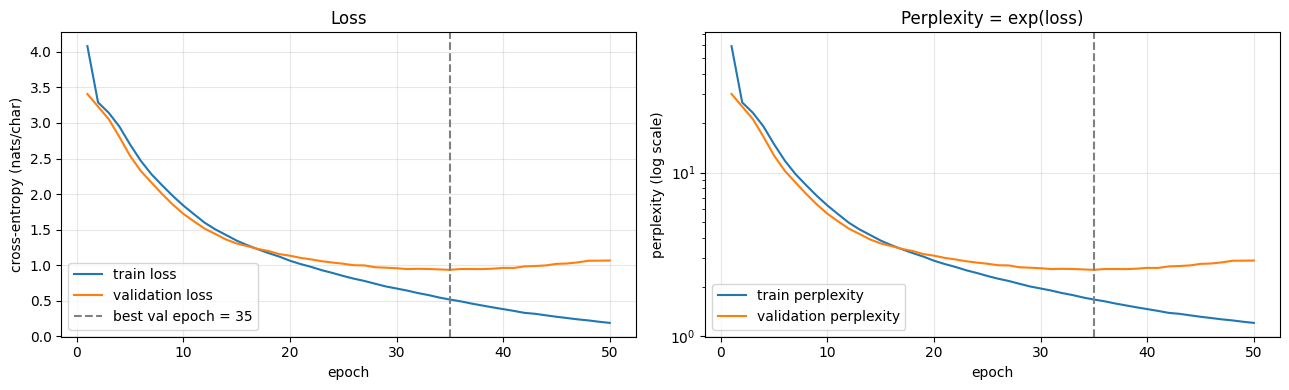

Best validation epoch : 35
Best validation loss  : 0.9357  -> perplexity 2.55, 1.350 bits/char
Final train loss      : 0.1897  -> perplexity 1.21
Final validation loss : 1.0665  -> perplexity 2.91


In [46]:
# Training curves: loss and perplexity (= exp(loss)) on training and validation data
hist = history.history
epochs_range = np.arange(1, len(hist["loss"]) + 1)
best_epoch = int(np.argmin(hist["val_loss"])) + 1
best_val_loss = float(np.min(hist["val_loss"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs_range, hist["loss"], label="train loss")
axes[0].plot(epochs_range, hist["val_loss"], label="validation loss")
axes[0].axvline(best_epoch, color="gray", ls="--", label=f"best val epoch = {best_epoch}")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy (nats/char)"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title("Loss")
axes[1].semilogy(epochs_range, np.exp(hist["loss"]), label="train perplexity")
axes[1].semilogy(epochs_range, np.exp(hist["val_loss"]), label="validation perplexity")
axes[1].axvline(best_epoch, color="gray", ls="--")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("perplexity (log scale)"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title("Perplexity = exp(loss)")
plt.tight_layout(); plt.show()

print(f"Best validation epoch : {best_epoch}")
print(f"Best validation loss  : {best_val_loss:.4f}  -> perplexity {np.exp(best_val_loss):.2f}, {best_val_loss / np.log(2):.3f} bits/char")
print(f"Final train loss      : {hist['loss'][-1]:.4f}  -> perplexity {np.exp(hist['loss'][-1]):.2f}")
print(f"Final validation loss : {hist['val_loss'][-1]:.4f}  -> perplexity {np.exp(hist['val_loss'][-1]):.2f}")

In [47]:
# Take one example after the training. Now the parameters are trained, so the prediction should be better.
for input_example_batch, target_example_batch in dataset.take(1):
    example_batch_predictions = model(input_example_batch)
    print(example_batch_predictions.shape, "# (batch_size, sequence_length, vocab_size)")

(32, 100, 69) # (batch_size, sequence_length, vocab_size)


In [48]:
# Let's have a look what is the current prediction after training: the output is much closer to the corpus
sampled_indices = tf.random.categorical(example_batch_predictions[0], num_samples=1)
print(sampled_indices.shape)
sampled_indices = tf.squeeze(sampled_indices, axis=-1).numpy()
print(sampled_indices)

(100, 1)
[56 60 57  2 42 50 50 63 46  2 56 50 53  2  5  2  9  2 61 43 60 57  2 53
 46 45  2 63 50 55 46  2 63 50 55 46 48 42 59  1  5  2  9  2 61 60 57  2
 60 59 50 46 45  2 56 59 46 48 42 55 56  1  5  2  9  2 10  2 61 60 57  2
 60 42 53 61  1 31 46 61 49 56 45 18  1  9  6  2 26 45 45  2 61 49 46  2
 61 56 54 42]


In [49]:
print("Input:\n", text_from_ids(input_example_batch[0]).numpy().decode('utf-8'))
print()
print("Next Char Predictions:\n", text_from_ids(sampled_indices).numpy().decode('utf-8'))

Input:
 tbsp olive oil
- 1 tbsp red wine vinegar
- 1 tsp dried oregano
- 1/2 tsp salt
Method:
1. Add the tom

Next Char Predictions:
 osp aiive oil - 1 tbsp led vine vinegar
- 1 tsp sried oregano
- 1 2 tsp salt
Method:
1. Hdd the toma


### 1.9 Generate the text through the model

Each time you call the model you pass in some text and an internal state. The model returns a prediction for the next character and its new state. Pass the prediction and state back in to continue generating text. `OneStep` is the class demo code. I only commented out a debug `print`.

In [50]:
class OneStep(tf.keras.Model):
  def __init__(self, model, chars_from_ids, ids_from_chars, temperature=1.0):
    super().__init__()
    self.temperature = temperature
    self.model = model
    self.chars_from_ids = chars_from_ids
    self.ids_from_chars = ids_from_chars

    # Create a mask to prevent "[UNK]" from being generated.
    skip_ids = self.ids_from_chars(['[UNK]'])[:, None]
    sparse_mask = tf.SparseTensor(
        # Put a -inf at each bad index.
        values=[-float('inf')]*len(skip_ids),
        indices=skip_ids,
        # Match the shape to the vocabulary
        dense_shape=[len(ids_from_chars.get_vocabulary())])
    self.prediction_mask = tf.sparse.to_dense(sparse_mask)

  @tf.function
  def generate_one_step(self, inputs, states=None):
    # Convert strings to token IDs.
    input_chars = tf.strings.unicode_split(inputs, 'UTF-8')
    input_ids = self.ids_from_chars(input_chars).to_tensor()

    # Run the model.
    # predicted_logits.shape is [batch, char, next_char_logits]
    predicted_logits, states = self.model(inputs=input_ids, states=states,
                                          return_state=True)
    # Only use the last prediction.
    predicted_logits = predicted_logits[:, -1, :]
    #print("predicted_logits shape: ", predicted_logits.shape)

    predicted_logits = predicted_logits/self.temperature
    # Apply the prediction mask: prevent "[UNK]" from being generated.
    predicted_logits = predicted_logits + self.prediction_mask

    # Sample the output logits to generate token IDs.
    predicted_ids = tf.random.categorical(predicted_logits, num_samples=1)
    predicted_ids = tf.squeeze(predicted_ids, axis=-1)

    # Convert from token ids to characters
    predicted_chars = self.chars_from_ids(predicted_ids)

    # Return the characters and model state.
    return predicted_chars, states

In [51]:
one_step_model = OneStep(model, chars_from_ids, ids_from_chars)

In [52]:
# Same loop as the class demo (150 characters), with a recipe title as the seed
start = time.time()
states = None
next_char = tf.constant(['Title: Mango Lentil Soup\n'])
result = [next_char]

for n in range(150):
  next_char, states = one_step_model.generate_one_step(next_char, states=states)

  result.append(next_char)

result = tf.strings.join(result)
end = time.time()
print(result[0].numpy().decode('utf-8'), '\n\n' + '_'*80)
print('\nRun time:', end - start)

Title: Mango Lentil Soup
Serves: 1 | Prep: 15 min | Cook: 10 min
Ingredients:
- 1 1/2 cups flour
- 2 tbsp corn astro wdle into sugar
- 1 garning sliced
- 1/2 cup corn tomatoes 

________________________________________________________________________________

Run time: 0.7366931438446045


**Generating a whole recipe with a stop condition.** The loop keeps sampling until the model writes the end-of-recipe marker `###` or reaches `MAX_CHARS`. The seeds are **titles that are not in my corpus**, so the model has to *compose* a new recipe.

In [53]:
STOP_TOKEN = "###"
MAX_CHARS = 900          # a typical recipe in my corpus is ~690 characters
GEN_TEMPERATURE = 0.7    # default sampling temperature used for comparisons

SEEDS = ["Title: Mango Lentil Soup\n",
         "Title: Spinach Mushroom Pasta\n",
         "Title: Coconut Rice Pudding\n",
         "Title: Paneer Fried Rice\n"]

def generate_recipe(one_step, seed, max_chars=MAX_CHARS, stop_token=STOP_TOKEN):
    """Generate character by character until the stop token or max_chars is reached."""
    states = None
    next_char = tf.constant([seed])
    generated = ""
    for _ in range(max_chars):
        next_char, states = one_step.generate_one_step(next_char, states=states)
        generated += next_char[0].numpy().decode("utf-8")
        if generated.endswith(stop_token):
            generated = generated[:-len(stop_token)]
            break
    return (seed + generated).rstrip()

final_one_step = OneStep(model, chars_from_ids, ids_from_chars, temperature=GEN_TEMPERATURE)
tf.random.set_seed(SEED)
start = time.time()
recipe = generate_recipe(final_one_step, SEEDS[0])
print(recipe)
print("_" * 80, f"\n{len(recipe)} characters, run time {time.time() - start:.1f} s")

Title: Mango Lentil Soup
Serves: 1 | Prep: 15 min | Cook: 10 min
Ingredients:
- 1 cup mint leaves
- 1 cup coriander ped
- 2 tbsp chopped coriander
- 2 tbsp lime juice
- 1 tsp salt
- 1/2 tsp black pepper
- 1 tsp corianter powder
- 1 tsp salt
- 1 tbsp oil
- 1 tbsp chocolate chips
Method:
1. Add the tomato and coriander low the malkand.
________________________________________________________________________________ 
335 characters, run time 1.3 s


**Effect of temperature.** Temperature divides the logits before sampling. Low values make the distribution sharper (safer, more repetitive, more copying), and high values flatten it (more novel, more spelling errors).

In [54]:
temperature_samples = {}
for temp in [0.2, 0.5, 0.8, 1.0, 1.3]:
    step = OneStep(model, chars_from_ids, ids_from_chars, temperature=temp)
    tf.random.set_seed(SEED)
    temperature_samples[temp] = generate_recipe(step, "Title: Spinach Mushroom Pasta\n", max_chars=500)
    print(f"===== temperature = {temp} =====")
    print(temperature_samples[temp])
    print()

===== temperature = 0.2 =====
Title: Spinach Mushroom Pasta
Serves: 4 | Prep: 10 min | Cook: 15 min
Ingredients:
- 1 cup ripe mango pulp
- 1 cup corn lentils, rinsed
- 1 can chopped tomatoes
- 4 cups vegetable stock
- 1 tsp salt
- 1/2 tsp black pepper
- 1 tsp salt
- 1 tbsp ghee
- 1 tsp cumin seeds
- 1 large onion, chopped
- 1 tbsp ginger garlic paste
- 2 medium tomatoes, pureed
- 1 tsp salt
- 2 cups water
- 1 tsp salt
Method:
1. Add the tomatoes, onion and green chili to a bowl.
2. Stir in the cornstarch mixted and serve with a spala it a small pan.
2. A

===== temperature = 0.5 =====
Title: Spinach Mushroom Pasta
Serves: 4 | Prep: 15 min | Cook: 15 min
Ingredients:
- 1 cup mint leaves
- 1 cup coriander ped
- 2 tbsp chopped coriander
- 2 tbsp lime juice
- 1 tsp salt
- 1/2 tsp black pepper
- 1 tsp sugar
- 1 tsp cinnamon powder
- 1 tbsp lemon juice
- 1 tsp salt
- 1/2 tsp black pepper
- 1/4 tsp salt
- 1 tbsp lemon juice
- 1 tbsp oil
Method:
1. Add the tomatoes, onion and green chili to a 

**Best-validation checkpoint vs. final model.** The final weights (epoch 50) have seen the training recipes many times and tend to *copy* them. The checkpoint with the lowest validation loss is the model that generalizes best to unseen recipes. I generate the same seeds with both. I also add the title of a **held-out validation recipe** that the model never saw, so its output can be compared with the real recipe.

In [55]:
# Re-create the model and load the best-validation weights
best_char_model = MyModel(vocab_size=vocab_size, embedding_dim=embedding_dim,
                          rnn_units=rnn_units, name="recipe_char_lstm_best")
best_char_model(tf.zeros((1, 1), dtype=tf.int32))          # build the variables
best_char_model.load_weights(BEST_CHAR_CKPT)
best_one_step = OneStep(best_char_model, chars_from_ids, ids_from_chars, temperature=GEN_TEMPERATURE)

heldout_title = val_recipes[0].splitlines()[0]             # e.g. "Title: Vegetable Pulao" (never trained on)
COMPARE_SEEDS = SEEDS + [heldout_title + "\n"]

final_samples, best_samples = {}, {}
tf.random.set_seed(SEED)
for s in COMPARE_SEEDS:
    final_samples[s] = generate_recipe(final_one_step, s)
tf.random.set_seed(SEED)
for s in COMPARE_SEEDS:
    best_samples[s] = generate_recipe(best_one_step, s)

for s in COMPARE_SEEDS:
    print("=" * 100)
    print(f"SEED: {s.strip()}")
    print("-" * 40, f"FINAL model (epoch {EPOCHS})", "-" * 40)
    print(final_samples[s])
    print("-" * 40, f"BEST-VALIDATION model (epoch {best_epoch})", "-" * 40)
    print(best_samples[s])

SEED: Title: Mango Lentil Soup
---------------------------------------- FINAL model (epoch 50) ----------------------------------------
Title: Mango Lentil Soup
Serves: 1 | Prep: 15 min | Cook: 10 min
Ingredients:
- 1 cup mint leaves
- 1 cup coriander ped
- 2 tbsp chopped coriander
- 2 tbsp lime juice
- 1 tsp salt
- 1/2 tsp black pepper
- 1 tsp corianter powder
- 1 tsp salt
- 1 tbsp oil
- 1 tbsp chocolate chips
Method:
1. Add the tomato and coriander low the malkand.
---------------------------------------- BEST-VALIDATION model (epoch 35) ----------------------------------------
Title: Mango Lentil Soup
Serves: 1 | Prep: 15 min | Cook: 20 min
Ingredients:
- 4 cups cooked chickpeas
- 1 tsp grated garlic paste
- 2 tbsp chopped coriander
- 2 tbsp sugar
- 1 tsp salt
- 1 tbsp butter
- 1 tsp cumin powder
- 1 tsp salt
- 2 eggs
- 1/2 tsp salt
Method:
1. Serve hot with bakil and bring uttir girge browl.
5. Sprinkle the chumas and soft on the maslaves add the cumin seeds.
2. Add the onion and g

In [56]:
print("The REAL held-out recipe (never seen during training), for comparison:\n")
print(val_recipes[0])

The REAL held-out recipe (never seen during training), for comparison:

Title: Vegetable Pulao
Serves: 4 | Prep: 15 min | Cook: 25 min
Ingredients:
- 1 cup basmati rice, soaked for 20 minutes
- 2 tbsp ghee
- 1 bay leaf
- 4 cloves
- 2 green cardamom pods
- 1 small cinnamon stick
- 1 medium onion, sliced
- 1 cup mixed vegetables
- 2 cups water
- 1 tsp salt
Method:
1. Heat the ghee in a pot and add the whole spices.
2. Add the onion and cook until light golden.
3. Add the vegetables and cook for 3 minutes.
4. Add the drained rice and stir gently for 1 minute.
5. Pour in the water and salt and bring to a boil.
6. Cover and cook on low heat for 12 minutes.
7. Rest for 5 minutes, then fluff with a fork.
Tip: Serve with cucumber raita.
###



### 1.10 Measuring generation quality
Perplexity does not tell us whether a *generated* recipe is any good (see my answer in 1.7). So I score every sample automatically against the recipe template:

| Metric | Meaning |
|---|---|
| `sections_present` | Share of the 5 template sections that appear (`Title:`, `Serves:`, `Ingredients:`, `Method:`, `Tip:`) |
| `serves_line_ok` | The line `Serves: N \| Prep: N min \| Cook: N min` is exactly well-formed |
| `ingredient_lines_well_formed` | Share of ingredient lines that start with `- <quantity> <word>` |
| `steps_numbered_1_to_n` | Method steps are numbered 1, 2, 3, … without gaps |
| `valid_word_rate` | Share of generated words that are real words from the training corpus (spelling) |
| `title_words_used_in_body` | Share of title words (e.g. *mango, lentil, soup*) used again in the recipe body (long-range coherence) |
| `copied_line_rate` | Share of generated lines (≥ 15 chars) copied **verbatim** from the training corpus (memorization) |

In [57]:
TRAIN_WORDS = {w.lower() for w in re.findall(r"[A-Za-z]+", train_text)}
TRAIN_LINES = {l.strip() for l in train_text.splitlines() if len(l.strip()) >= 15}
SERVES_RE = re.compile(r"^Serves: \d+ \| Prep: \d+ min \| Cook: \d+ min$")
INGREDIENT_RE = re.compile(r"^- (\d+ \d+/\d+|\d+/\d+|\d+) [a-z]")
STEP_RE = re.compile(r"^(\d+)\. [A-Z]")
SECTIONS = ["Title:", "Serves:", "Ingredients:", "Method:", "Tip:"]
GENERIC_TITLE_WORDS = {"with", "and", "the", "of", "style"}

def recipe_quality(text, seed=""):
    """Automatic, template-based quality metrics for one generated recipe."""
    lines = [l.strip() for l in text.strip().splitlines() if l.strip()]
    generated = text[len(seed):] if seed and text.startswith(seed) else text   # judge only what the model wrote
    gen_lines = [l.strip() for l in generated.splitlines() if len(l.strip()) >= 15]
    words = re.findall(r"[A-Za-z]+", generated)

    has = {s: any(l.startswith(s) for l in lines) for s in SECTIONS}
    ingredient_lines = []
    if has["Ingredients:"]:
        start_i = next(i for i, l in enumerate(lines) if l.startswith("Ingredients:")) + 1
        end_i = next((i for i, l in enumerate(lines) if i >= start_i and l.startswith("Method:")), len(lines))
        ingredient_lines = [l for l in lines[start_i:end_i] if l.startswith("-")]
    step_numbers = [int(m.group(1)) for l in lines if (m := STEP_RE.match(l))]
    title_words = [w.lower() for w in re.findall(r"[A-Za-z]+", lines[0])][1:] if lines else []   # drop "Title"
    title_words = [w for w in title_words if w not in GENERIC_TITLE_WORDS]
    body = " ".join(lines[1:]).lower()

    return {
        "sections_present": sum(has.values()) / len(SECTIONS),
        "serves_line_ok": float(any(SERVES_RE.match(l) for l in lines)),
        "n_ingredients": len(ingredient_lines),
        "ingredient_lines_well_formed": float(np.mean([bool(INGREDIENT_RE.match(l)) for l in ingredient_lines])) if ingredient_lines else 0.0,
        "n_steps": len(step_numbers),
        "steps_numbered_1_to_n": float(len(step_numbers) > 0 and step_numbers == list(range(1, len(step_numbers) + 1))),
        "valid_word_rate": float(np.mean([w.lower() in TRAIN_WORDS for w in words])) if words else 0.0,
        "title_words_used_in_body": float(np.mean([bool(re.search(rf"\b{re.escape(w.rstrip('s'))}", body)) for w in title_words])) if title_words else np.nan,
        "copied_line_rate": float(np.mean([l in TRAIN_LINES for l in gen_lines])) if gen_lines else 0.0,
        "length_chars": len(text),
    }

def mean_quality(samples, seeds):
    return pd.DataFrame([recipe_quality(samples[s], s) for s in seeds]).mean(numeric_only=True)

# Sanity check: the real recipes should score (almost) perfectly on structure and have copy rate 1.0 for training recipes
print("Real training recipe :", {k: round(v, 2) for k, v in recipe_quality(train_recipes[0]).items()})
print("Real held-out recipe :", {k: round(v, 2) for k, v in recipe_quality(val_recipes[0]).items()})

Real training recipe : {'sections_present': 1.0, 'serves_line_ok': 1.0, 'n_ingredients': 11, 'ingredient_lines_well_formed': 1.0, 'n_steps': 7, 'steps_numbered_1_to_n': 1.0, 'valid_word_rate': 1.0, 'title_words_used_in_body': 1.0, 'copied_line_rate': 1.0, 'length_chars': 885}
Real held-out recipe : {'sections_present': 1.0, 'serves_line_ok': 1.0, 'n_ingredients': 10, 'ingredient_lines_well_formed': 1.0, 'n_steps': 7, 'steps_numbered_1_to_n': 1.0, 'valid_word_rate': 0.99, 'title_words_used_in_body': 0.5, 'copied_line_rate': 0.2, 'length_chars': 671}


In [58]:
FINAL_ROW = f"char-LSTM-1024 final (epoch {EPOCHS})"
BEST_ROW = f"char-LSTM-1024 best-val (epoch {best_epoch})"
real_heldout = {r.splitlines()[0] + "\n": r.replace("###", "").strip() for r in val_recipes}
quality_table = pd.DataFrame({
    FINAL_ROW: mean_quality(final_samples, COMPARE_SEEDS),
    BEST_ROW: mean_quality(best_samples, COMPARE_SEEDS),
    "REAL held-out recipes (reference)": mean_quality(real_heldout, list(real_heldout)),
}).T
print(f"Model rows: average over {len(COMPARE_SEEDS)} seeds at temperature {GEN_TEMPERATURE}. "
      f"Reference row: the {len(real_heldout)} real validation recipes (shows the ceiling, and that even real "
      "new recipes reuse some stock lines).")
display(quality_table.round(2))

temp_table = pd.DataFrame({t: recipe_quality(s, "Title: Spinach Mushroom Pasta\n") for t, s in temperature_samples.items()}).T
temp_table.index.name = "temperature (final model, 500 chars max)"
display(temp_table[["sections_present", "ingredient_lines_well_formed", "valid_word_rate", "copied_line_rate"]].round(2))

Model rows: average over 5 seeds at temperature 0.7. Reference row: the 6 real validation recipes (shows the ceiling, and that even real new recipes reuse some stock lines).


,sections_present,serves_line_ok,n_ingredients,ingredient_lines_well_formed,n_steps,steps_numbered_1_to_n,valid_word_rate,title_words_used_in_body,copied_line_rate,length_chars
char-LSTM-1024 final (epoch 50),0.92,1.0,9.80,1.0,6.00,0.2,0.90,0.07,0.42,656.20
char-LSTM-1024 best-val (epoch 35),0.76,0.8,17.40,0.8,5.60,0.2,0.85,0.17,0.32,799.60
REAL held-out recipes (reference),1.00,1.0,9.17,1.0,6.33,1.0,0.95,0.76,0.22,641.67


,sections_present,ingredient_lines_well_formed,valid_word_rate,copied_line_rate
"temperature (final model, 500 chars max)",,,,
0.2,0.8,1.00,0.97,0.83
0.5,0.8,1.00,0.97,0.69
0.8,0.8,1.00,0.83,0.40
1.0,0.8,0.95,0.79,0.47
1.3,0.4,0.00,0.58,0.00


## 4. Optional 1: experimenting with different RNN/LSTM configurations

`FlexibleRNNModel` has the **same interface** as `MyModel` (`states`, `return_state`), so the class `OneStep` generator works unchanged. The cell type (SimpleRNN / GRU / LSTM), width, depth and dropout can be changed. Every configuration uses the same data, optimizer, seed and **the same 50 epochs as the main model**. For each one I keep the best-validation checkpoint and generate the same 4 seeds at temperature 0.7.

| Config | Why |
|---|---|
| SimpleRNN-512 | Plain RNN: tests the vanishing-gradient handicap |
| GRU-512 | Gated, 3 weight blocks |
| LSTM-512 | Gated, 4 weight blocks, same width as the others |
| LSTM-2x512 + dropout 0.2 | Deeper, with regularization against overfitting |
| *(LSTM-1024 from 1.8)* | *The main model, wider* |

In [59]:
class FlexibleRNNModel(tf.keras.Model):
    """Same interface as MyModel, but the recurrent cell type, depth and dropout are configurable."""
    def __init__(self, vocab_size, embedding_dim, rnn_units, cell_type="lstm", num_layers=1, dropout=0.0, name=None):
        super().__init__(name=name)
        rnn_class = {"simplernn": tf.keras.layers.SimpleRNN,
                     "gru": tf.keras.layers.GRU,
                     "lstm": tf.keras.layers.LSTM}[cell_type]
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.rnn_layers = [rnn_class(rnn_units, return_sequences=True, return_state=True, dropout=dropout)
                           for _ in range(num_layers)]
        self.dense = tf.keras.layers.Dense(vocab_size)

    def call(self, inputs, states=None, return_state=False, training=None):
        x = self.embedding(tf.cast(inputs, tf.int32), training=training)
        new_states = []
        for i, layer in enumerate(self.rnn_layers):
            initial_state = None if states is None else states[i]
            out = layer(x, initial_state=initial_state, training=training)
            x, layer_state = out[0], list(out[1:])      # LSTM -> [h, c]; GRU / SimpleRNN -> [h]
            new_states.append(layer_state)
        logits = self.dense(x, training=training)
        return (logits, new_states) if return_state else logits

In [60]:
EXPERIMENTS = [
    dict(name="SimpleRNN-512",            cell_type="simplernn", rnn_units=512, num_layers=1, dropout=0.0),
    dict(name="GRU-512",                  cell_type="gru",       rnn_units=512, num_layers=1, dropout=0.0),
    dict(name="LSTM-512",                 cell_type="lstm",      rnn_units=512, num_layers=1, dropout=0.0),
    dict(name="LSTM-2x512 + dropout 0.2", cell_type="lstm",      rnn_units=512, num_layers=2, dropout=0.2),
]
EXP_EPOCHS = EPOCHS     # same budget as the main model (50); the checkpoint keeps each model's best epoch

class EveryNEpochs(tf.keras.callbacks.Callback):
    def __init__(self, n=10): super().__init__(); self.n = n
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.n == 0:
            print(f"   epoch {epoch + 1:3d}: loss {logs['loss']:.3f}  val_loss {logs['val_loss']:.3f}")

exp_results = {}
for cfg in EXPERIMENTS:
    print(f"=== {cfg['name']} ===")
    tf.keras.utils.set_random_seed(SEED)
    safe_name = re.sub(r"[^A-Za-z0-9_]", "_", cfg["name"])
    m = FlexibleRNNModel(vocab_size, embedding_dim, cfg["rnn_units"], cfg["cell_type"],
                         cfg["num_layers"], cfg["dropout"], name=safe_name)
    m.compile(optimizer="adam", loss=loss)
    ckpt = f"best_{safe_name}.weights.h5"
    callbacks = [tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True),
                 EveryNEpochs(10)]
    t0 = time.time()
    h = m.fit(dataset, epochs=EXP_EPOCHS, validation_data=val_dataset, callbacks=callbacks, verbose=0)
    train_time = time.time() - t0

    m.load_weights(ckpt)                                        # best-validation weights
    step = OneStep(m, chars_from_ids, ids_from_chars, temperature=GEN_TEMPERATURE)
    tf.random.set_seed(SEED)
    samples = {s: generate_recipe(step, s) for s in SEEDS}

    exp_results[cfg["name"]] = dict(history=h.history, params=m.count_params(), train_time=train_time, samples=samples,
                                    best_epoch=int(np.argmin(h.history["val_loss"])) + 1,
                                    best_val_loss=float(np.min(h.history["val_loss"])))
    print(f"   params {m.count_params():,} | best val loss {exp_results[cfg['name']]['best_val_loss']:.3f} "
          f"(epoch {exp_results[cfg['name']]['best_epoch']}) | {train_time:.0f} s")

=== SimpleRNN-512 ===
   epoch  10: loss 1.355  val_loss 1.368
   epoch  20: loss 0.930  val_loss 1.158
   epoch  30: loss 0.605  val_loss 1.149
   epoch  40: loss 0.379  val_loss 1.252
   epoch  50: loss 0.234  val_loss 1.390
   params 446,789 | best val loss 1.127 (epoch 23) | 24 s
=== GRU-512 ===
   epoch  10: loss 1.719  val_loss 1.617
   epoch  20: loss 1.078  val_loss 1.129
   epoch  30: loss 0.739  val_loss 0.951
   epoch  40: loss 0.524  val_loss 0.891
   epoch  50: loss 0.368  val_loss 0.899
   params 1,235,781 | best val loss 0.883 (epoch 45) | 18 s
=== LSTM-512 ===
   epoch  10: loss 1.847  val_loss 1.754
   epoch  20: loss 1.210  val_loss 1.226
   epoch  30: loss 0.887  val_loss 1.042
   epoch  40: loss 0.672  val_loss 0.974
   epoch  50: loss 0.492  val_loss 0.957
   params 1,627,973 | best val loss 0.953 (epoch 43) | 27 s
=== LSTM-2x512 + dropout 0.2 ===
   epoch  10: loss 2.152  val_loss 2.027
   epoch  20: loss 1.345  val_loss 1.319
   epoch  30: loss 0.924  val_loss 1.

,params,sec/epoch,best val epoch,best val loss,best val perplexity,bits/char,sections_present,ingredient_lines_well_formed,steps_numbered_1_to_n,valid_word_rate,title_words_used_in_body,copied_line_rate
SimpleRNN-512,446789,0.487,23,1.127,3.087,1.626,0.65,0.750,0.00,0.611,0.083,0.155
GRU-512,1235781,0.365,45,0.883,2.417,1.273,0.75,0.750,0.00,0.945,0.083,0.229
LSTM-512,1627973,0.544,43,0.953,2.594,1.375,0.75,0.875,0.00,0.786,0.000,0.172
LSTM-2x512 + dropout 0.2,3727173,0.765,45,0.984,2.675,1.420,0.80,1.000,0.00,0.846,0.000,0.204
"LSTM-1024 (main model, 1.8)",5335365,1.013,35,0.936,2.549,1.350,0.75,0.750,0.25,0.843,0.083,0.315


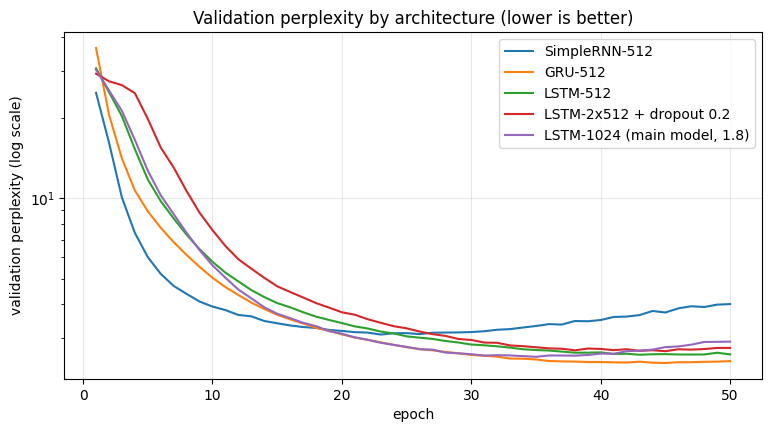

In [61]:
# Add the main model (best-validation checkpoint of 1.8, generated on the same 4 seeds)
exp_results["LSTM-1024 (main model, 1.8)"] = dict(
    history=hist, params=model.count_params(), train_time=main_train_time,
    samples={s: best_samples[s] for s in SEEDS}, best_epoch=best_epoch, best_val_loss=best_val_loss)

rows = {}
for name, r in exp_results.items():
    q = mean_quality(r["samples"], SEEDS)
    n_epochs = len(r["history"]["loss"])
    rows[name] = {"params": r["params"],
                  "sec/epoch": r["train_time"] / n_epochs,
                  "best val epoch": r["best_epoch"],
                  "best val loss": r["best_val_loss"],
                  "best val perplexity": np.exp(r["best_val_loss"]),
                  "bits/char": r["best_val_loss"] / np.log(2),
                  "sections_present": q["sections_present"],
                  "ingredient_lines_well_formed": q["ingredient_lines_well_formed"],
                  "steps_numbered_1_to_n": q["steps_numbered_1_to_n"],
                  "valid_word_rate": q["valid_word_rate"],
                  "title_words_used_in_body": q["title_words_used_in_body"],
                  "copied_line_rate": q["copied_line_rate"]}
arch_table = pd.DataFrame(rows).T
arch_display = arch_table.round(3)
arch_display["params"] = arch_table["params"].astype(int)
arch_display["best val epoch"] = arch_table["best val epoch"].astype(int)
display(arch_display)

plt.figure(figsize=(9, 4.5))
for name, r in exp_results.items():
    v = r["history"]["val_loss"]
    plt.plot(np.arange(1, len(v) + 1), np.exp(v), label=name)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("validation perplexity (log scale)")
plt.title("Validation perplexity by architecture (lower is better)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [62]:
# Side-by-side samples for the first seed (best-validation weights, temperature 0.7)
for name, r in exp_results.items():
    print("=" * 30, name, "=" * 30)
    print(r["samples"][SEEDS[0]])
    print()

============================== SimpleRNN-512 ==============================
Title: Mango Lentil Soup
Serves: 4 | Prep: 15 min | Cook: 20 min
Ingredients:
- 1 cup mile on ale the and add the rice on to a boil.
7. Semon tummeric powder
- 1/4 tsp turmeric powder
- 1 tsp salt
- 1/2 tsp curin seeds
- 1 dsped chili, dine ed rince intee ven.

============================== GRU-512 ==============================
Title: Mango Lentil Soup
Serves: 1 | Prep: 15 min | Cook: 20 min
Ingredients:
- 1 cup grated carrots in turner and salt.
4. Spread the spices and cook until the rice it creamy.
4. Bake for 15 minutes, stock on top.
2. Add the garlic and cooked rice woth the each salte.
4. Add the garlic, cumin and garlic and creamy and selve.
3. Pour the dal with the water and salt.
3. Simmer for 30 minutes until the cheese pals, thinly sliced
- 1 green chili flakes
- 1 tsp mustard seeds
- 1/2 tsp black pepper
Method:
1. Add the garlic and cook flour until the pan and salt.
3. Spread the best taste gin

## 5. Optional 2: word-level tokenization vs character-level

Here every **word, number, punctuation mark and newline** is a token. The newline token is what lets the model learn the line layout of the template. Fractions like `1/2` and the marker `###` are kept as single tokens. The pipeline is the same as the class demo (`StringLookup` → `batch(seq_length+1)` → `split_input_target`), and the model is the class `MyModel`, just with a word vocabulary.

In [63]:
TOKEN_PATTERN = re.compile(r"###|\n|\d+/\d+|\d+|[A-Za-z]+|[^\sA-Za-z\d]")
NO_SPACE_BEFORE = {",", ".", ":", ";", ")", "%", "?", "!"}

def word_tokenize(text):
    return TOKEN_PATTERN.findall(text)

def detokenize(tokens):
    text = ""
    for tok in tokens:
        if tok == "\n":
            text = text.rstrip(" ") + "\n"
        elif text == "" or text.endswith("\n") or text.endswith("(") or tok in NO_SPACE_BEFORE:
            text += tok
        else:
            text += " " + tok
    return text

train_tokens = word_tokenize(train_text)
val_tokens = word_tokenize(val_text)
word_vocab = sorted(set(train_tokens))                 # vocabulary from TRAINING text only

print("Example tokens:", word_tokenize("- 1 1/2 cups basmati rice, soaked\n1. Heat the oil.\n###"))
roundtrip = [l for l in doc.splitlines() if detokenize(word_tokenize(l)) == l]
print(f"Tokenize -> detokenize round trip is exact for {len(roundtrip) / len(doc.splitlines()):.1%} of corpus lines")
print(f"Training tokens: {len(train_tokens):,} | validation tokens: {len(val_tokens):,}")
print(f"Word vocabulary: {len(word_vocab):,} tokens (+[UNK])  vs  {vocab_size} for characters")
word_vocab_set = set(word_vocab)
oov = [t for t in val_tokens if t not in word_vocab_set]
print(f"Validation tokens not in the training vocabulary (become [UNK]): {len(oov)} = {len(oov) / len(val_tokens):.1%}  e.g. {sorted(set(oov))[:12]}")

Example tokens: ['-', '1', '1/2', 'cups', 'basmati', 'rice', ',', 'soaked', '\n', '1', '.', 'Heat', 'the', 'oil', '.', '\n', '###']
Tokenize -> detokenize round trip is exact for 99.9% of corpus lines
Training tokens: 10,505 | validation tokens: 1,078
Word vocabulary: 855 tokens (+[UNK])  vs  69 for characters
Validation tokens not in the training vocabulary (become [UNK]): 45 = 4.2%  e.g. ['190', 'Bean', 'Bell', 'Berry', 'Black', 'Choose', 'Corn', 'Dressing', 'Fill', 'Peppers', 'Pulao', 'Quinoa']


In [64]:
word_ids_from_tokens = tf.keras.layers.StringLookup(vocabulary=word_vocab, mask_token=None)
tokens_from_word_ids = tf.keras.layers.StringLookup(vocabulary=word_ids_from_tokens.get_vocabulary(),
                                                    invert=True, mask_token=None)
word_vocab_size = len(word_ids_from_tokens.get_vocabulary())

WORD_SEQ_LENGTH = 40     # ~40 tokens covers about as much text as 100-200 characters

def make_word_dataset(tokens):
    tok_ids = word_ids_from_tokens(tf.constant(tokens))
    seqs = tf.data.Dataset.from_tensor_slices(tok_ids).batch(WORD_SEQ_LENGTH + 1, drop_remainder=True)
    return seqs.map(split_input_target)

word_dataset = (make_word_dataset(train_tokens).shuffle(BUFFER_SIZE)
                .batch(BATCH_SIZE, drop_remainder=True).prefetch(tf.data.AUTOTUNE))
word_val_dataset = make_word_dataset(val_tokens).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
print("word training batches per epoch:", int(word_dataset.cardinality()))

for x_w, y_w in word_dataset.take(1):
    print("Input :", detokenize([t.decode() for t in tokens_from_word_ids(x_w[0]).numpy()])[:200])

word training batches per epoch: 8
Input : .
5. Add the noodles and toss until coated.
6. Top with spring onions and sesame seeds.
7. Serve warm.
Tip: Toast the sesame seeds in a dry pan


In [65]:
WORD_EPOCHS = 60
BEST_WORD_CKPT = "best_word_lstm.weights.h5"
tf.keras.utils.set_random_seed(SEED)
word_model = MyModel(vocab_size=word_vocab_size, embedding_dim=128, rnn_units=512, name="recipe_word_lstm")
word_model.compile(optimizer="adam", loss=loss)

t0 = time.time()
word_history = word_model.fit(
    word_dataset, epochs=WORD_EPOCHS, validation_data=word_val_dataset, verbose=0,
    callbacks=[tf.keras.callbacks.ModelCheckpoint(BEST_WORD_CKPT, monitor="val_loss", save_best_only=True, save_weights_only=True),
               EveryNEpochs(10)])
word_train_time = time.time() - t0
word_model.load_weights(BEST_WORD_CKPT)

word_best_epoch = int(np.argmin(word_history.history["val_loss"])) + 1
word_best_val_loss = float(np.min(word_history.history["val_loss"]))
print(f"params {word_model.count_params():,} | best val loss {word_best_val_loss:.3f} nats/word "
      f"(epoch {word_best_epoch}) -> word perplexity {np.exp(word_best_val_loss):.1f} | {word_train_time:.0f} s")

   epoch  10: loss 3.877  val_loss 4.032
   epoch  20: loss 2.675  val_loss 2.956
   epoch  30: loss 2.128  val_loss 2.710
   epoch  40: loss 1.760  val_loss 2.630
   epoch  50: loss 1.471  val_loss 2.607
   epoch  60: loss 1.231  val_loss 2.627
params 1,861,464 | best val loss 2.604 nats/word (epoch 47) -> word perplexity 13.5 | 16 s


In [66]:
class WordOneStep(tf.keras.Model):
    """Like OneStep, but works on word-token IDs directly."""
    def __init__(self, model, vocab_size, temperature=1.0):
        super().__init__()
        self.model = model
        self.temperature = temperature
        mask = np.zeros([vocab_size], dtype=np.float32)
        mask[0] = -np.inf                                   # index 0 is [UNK] -> never generate it
        self.prediction_mask = tf.constant(mask)

    @tf.function
    def generate_one_step(self, input_ids, states=None):
        predicted_logits, states = self.model(inputs=input_ids, states=states, return_state=True)
        predicted_logits = predicted_logits[:, -1, :] / self.temperature + self.prediction_mask
        predicted_ids = tf.random.categorical(predicted_logits, num_samples=1)   # shape (1, 1)
        return predicted_ids, states

def generate_recipe_words(word_step, seed, max_tokens=300):
    seed_tokens = word_tokenize(seed)
    input_ids = word_ids_from_tokens(tf.constant([seed_tokens]))
    states, out_tokens = None, []
    for _ in range(max_tokens):
        next_id, states = word_step.generate_one_step(input_ids, states=states)
        tok = tokens_from_word_ids(next_id)[0, 0].numpy().decode("utf-8")
        if tok == STOP_TOKEN:
            break
        out_tokens.append(tok)
        input_ids = next_id
    return detokenize(seed_tokens + out_tokens).rstrip()

word_step = WordOneStep(word_model, word_vocab_size, temperature=GEN_TEMPERATURE)
print("Seed words that are NOT in the word vocabulary (the word model only sees [UNK] for them):",
      sorted({t for s in SEEDS for t in word_tokenize(s) if t not in word_vocab_set}) or "none")
tf.random.set_seed(SEED)
word_samples = {s: generate_recipe_words(word_step, s) for s in SEEDS}
for s in SEEDS[:2]:
    print("=" * 30, "WORD-level LSTM", "=" * 30)
    print(word_samples[s])
    print("=" * 30, "CHAR-level LSTM (best-val)", "=" * 30)
    print(best_samples[s])
    print()

Seed words that are NOT in the word vocabulary (the word model only sees [UNK] for them): ['Pudding']
============================== WORD-level LSTM ==============================
Title: Mango Lentil Soup
Serves: 4 | Prep: 10 min | Cook: 20 min
Ingredients:
- 1 cup brown sugar
- 2 cups cooked, minced
- 2 tbsp chopped juice
- 1 tsp cumin soda
- 1 tsp salt
- 1/2 tsp black pepper
Method:
1. Boil the noodles in a pot and add soft.
2. Add the mozzarella, bell vegetables.
2. Add the tomato, salt and add the cumin seeds and sprinkle glaze.
5. Add the onion, bell oil and cook in a bowl.
============================== CHAR-level LSTM (best-val) ==============================
Title: Mango Lentil Soup
Serves: 1 | Prep: 15 min | Cook: 20 min
Ingredients:
- 4 cups cooked chickpeas
- 1 tsp grated garlic paste
- 2 tbsp chopped coriander
- 2 tbsp sugar
- 1 tsp salt
- 1 tbsp butter
- 1 tsp cumin powder
- 1 tsp salt
- 2 eggs
- 1/2 tsp salt
Method:
1. Serve hot with bakil and bring uttir girge browl.
5. 

In [67]:
# Compare on the same seeds and temperature.
# Perplexities are per-token, so convert both to bits per CHARACTER of validation text before comparing.
val_chars_per_word_token = len(val_text) / len(val_tokens)
char_bpc = best_val_loss / np.log(2)
word_bpc = (word_best_val_loss / val_chars_per_word_token) / np.log(2)

token_compare = pd.DataFrame({
    "char-level LSTM-1024 (best-val)": {
        "vocab size": vocab_size, "params": model.count_params(),
        "val perplexity (per own token)": np.exp(best_val_loss), "val bits per character": char_bpc,
        **mean_quality(best_samples, SEEDS).to_dict()},
    "word-level LSTM-512 (best-val)": {
        "vocab size": word_vocab_size, "params": word_model.count_params(),
        "val perplexity (per own token)": np.exp(word_best_val_loss), "val bits per character": word_bpc,
        **mean_quality(word_samples, SEEDS).to_dict()},
}).T
token_compare = token_compare.astype({"vocab size": int, "params": int})
display(token_compare[["vocab size", "params", "val perplexity (per own token)", "val bits per character",
                       "sections_present", "ingredient_lines_well_formed", "steps_numbered_1_to_n",
                       "valid_word_rate", "title_words_used_in_body", "copied_line_rate"]].round(3))
print(f"Note: one word token covers {val_chars_per_word_token:.2f} characters of validation text on average.")
print("Word-level bits/char is slightly optimistic because rare validation words become [UNK], which is easy to predict.")

,vocab size,params,val perplexity (per own token),val bits per character,sections_present,ingredient_lines_well_formed,steps_numbered_1_to_n,valid_word_rate,title_words_used_in_body,copied_line_rate
char-level LSTM-1024 (best-val),69,5335365,2.549,1.350,0.75,0.75,0.25,0.843,0.083,0.315
word-level LSTM-512 (best-val),856,1861464,13.523,1.044,0.90,0.75,0.00,1.000,0.167,0.139


Note: one word token covers 3.60 characters of validation text on average.
Word-level bits/char is slightly optimistic because rare validation words become [UNK], which is easy to predict.


## 6. Using the OpenAI API (same idea as the class demo's image step)

1. **Image:** turn a generated recipe into a picture of the dish (class demo: *"Generate image based on our recipe description"*).
2. **GPT as a blind judge:** an independent, stronger model scores anonymized samples on structure, coherence, fluency and plausibility. A **real held-out recipe** is mixed in as a control.

**API key.** The notebook looks for the key in this order: Colab *Secrets* (`OPENAI_API_KEY`) → environment variable / `.env` file (as in the class demo) → a hidden prompt. If no key is given, this part is skipped and the rest of the notebook is unaffected.

In [69]:
IMAGE_MODELS = ["gpt-image-2.5-flare", "gpt-image-2", "gpt-image-1"]   # first one = model used in the class demo
CHAT_MODELS = ["gpt-6-luna", "gpt-4o-mini"]                             # tried in order until one works
ASK_FOR_KEY_IF_MISSING = True

def get_openai_api_key():
    key = None
    try:                                             # 1) Google Colab secret
        from google.colab import userdata
        try:
            key = userdata.get("OPENAI_API_KEY")
        except Exception as e:
            print("Colab secret OPENAI_API_KEY not available:", type(e).__name__)
    except ImportError:
        pass
    if not key:                                      # 2) environment variable / .env file (class demo approach)
        try:
            from dotenv import load_dotenv
            load_dotenv()
        except ImportError:
            pass
        key = os.environ.get("OPENAI_API_KEY")
    if not key and ASK_FOR_KEY_IF_MISSING:           # 3) hidden prompt
        try:
            from getpass import getpass
            key = getpass("Paste your OpenAI API key (or press Enter to skip Part 6): ").strip()
        except Exception:
            key = None
    return key or None

client = None
api_key = get_openai_api_key()
if api_key:
    from openai import OpenAI
    client = OpenAI(api_key=api_key)
    print("OpenAI client ready.")
else:
    print("No OpenAI API key -> Part 6 will be skipped (everything else is unaffected).")

Colab secret OPENAI_API_KEY not available: SecretNotFoundError
Paste your OpenAI API key (or press Enter to skip Part 6): ··········
OpenAI client ready.


### 6.1 Generate an image of the generated recipe

In [70]:
# Pick the best-formed character-level sample (structure + spelling) as the "menu item" to illustrate
candidates = {**{("best-val", s): t for s, t in best_samples.items()},
              **{("final", s): t for s, t in final_samples.items()}}
def _score(item):
    (_, seed), text = item
    q = recipe_quality(text, seed)
    return q["sections_present"] + q["ingredient_lines_well_formed"] + q["valid_word_rate"]
(image_source, image_seed), recipe_for_image = max(candidates.items(), key=_score)
pic_desc = ("Please draw one plate of the dish described by this recipe, as a realistic, appetizing food photo "
            "on a kitchen table. No text in the image.\n\n" + recipe_for_image)
print(f"Recipe chosen for the image (from the {image_source} model):\n")
print(pic_desc)

Recipe chosen for the image (from the final model):

Please draw one plate of the dish described by this recipe, as a realistic, appetizing food photo on a kitchen table. No text in the image.

Title: Vegetable Pulao
Serves: 4 | Prep: 15 min | Cook: 0 min
Ingredients:
- 1 cup ripe mango pulp
- 1 1/4 cup smolled oasta
- 1/2 tsp sugar
- 1 tsp salt
- 2 tbsp cornstarch
Method:
1. Heat the oven to 210 C.
2. Place the flatbreads on a baking prain and stir fre for 3 minutes.
4. Add the lemon juice and led in the pata with a fork until golden.
3. Add the tomatoes and cook for 10 minutes until they break doan.
4. Pour the the mizzarela and toss until cream and serve hot.
Tip: Add the mashed and simmer for 10 minutes so the for jumell colets.


Image model used: gpt-image-2.5-flare


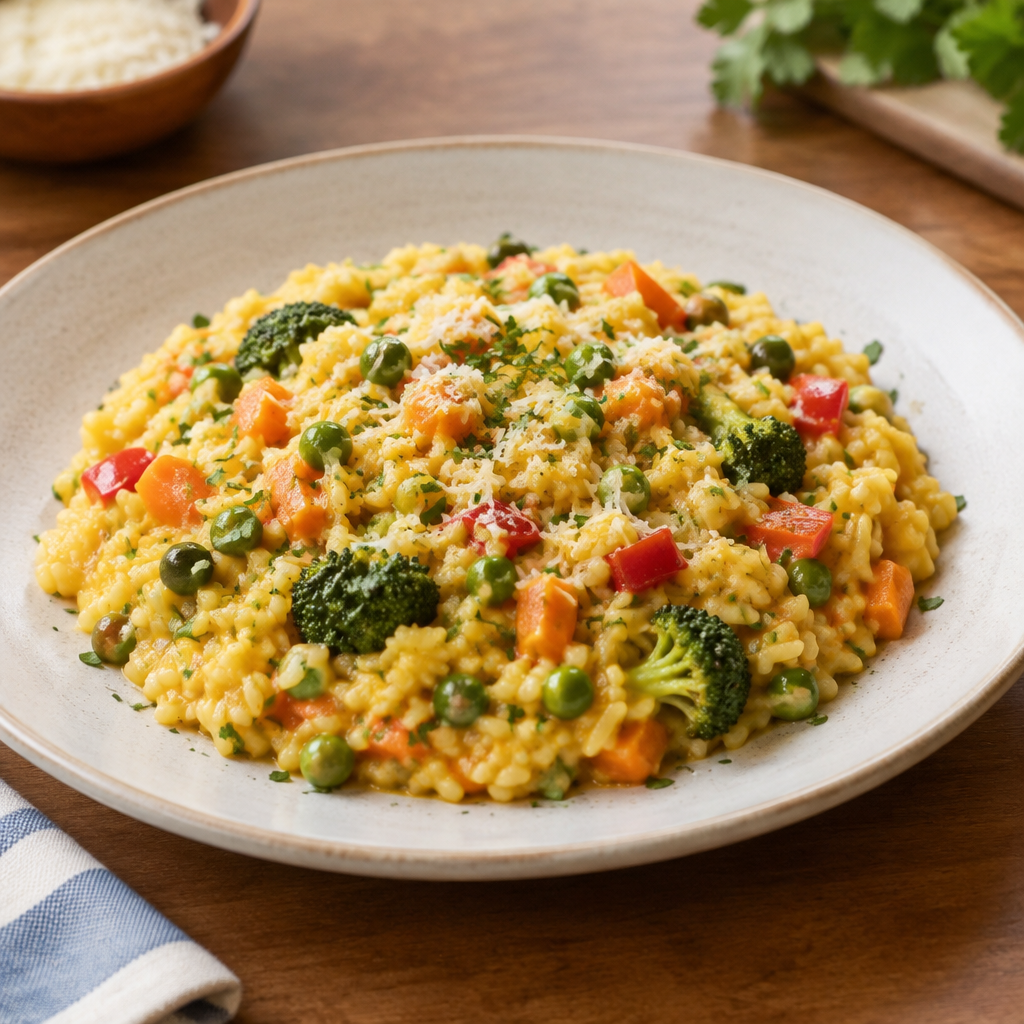

In [71]:
import io, base64, urllib.request
from PIL import Image

generated_image = None
if client is None:
    print("Skipped: no OpenAI API key.")
else:
    for image_model in IMAGE_MODELS:
        try:
            # 1) Generate image
            img_resp = client.images.generate(model=image_model, prompt=pic_desc, size="1024x1024")
            b64 = img_resp.data[0].b64_json
            if b64:
                generated_image = Image.open(io.BytesIO(base64.b64decode(b64)))
            elif getattr(img_resp.data[0], "url", None):
                with urllib.request.urlopen(img_resp.data[0].url) as r:
                    generated_image = Image.open(io.BytesIO(r.read()))
            print("Image model used:", image_model)
            break
        except Exception as e:
            print(f"{image_model} failed -> {type(e).__name__}: {str(e)[:200]}")
    # 2) Display (base64 -> PIL)
    if generated_image is not None:
        generated_image.save("generated_recipe_image.png")
        display(generated_image)

### 6.2 GPT as a blind judge of the generated recipes

In [72]:
def ask_chat_json(system_msg, user_msg):
    """Call the first chat model that works and return (model_name, parsed JSON dict)."""
    for chat_model in CHAT_MODELS:
        try:
            resp = client.chat.completions.create(
                model=chat_model,
                messages=[{"role": "system", "content": system_msg},
                          {"role": "user", "content": user_msg}],
                response_format={"type": "json_object"})
            content = resp.choices[0].message.content
            match = re.search(r"\{.*\}", content, re.S)
            return chat_model, json.loads(match.group(0) if match else content)
        except Exception as e:
            print(f"{chat_model} failed -> {type(e).__name__}: {str(e)[:200]}")
    return None, None

judge_table = None
if client is None:
    print("Skipped: no OpenAI API key.")
else:
    judge_seed = SEEDS[0]
    entries = {
        f"char-LSTM-1024 final (epoch {EPOCHS})": final_samples[judge_seed],
        f"char-LSTM-1024 best-val (epoch {best_epoch})": best_samples[judge_seed],
        "SimpleRNN-512 best-val": exp_results["SimpleRNN-512"]["samples"][judge_seed],
        "word-LSTM-512 best-val": word_samples[judge_seed],
        "REAL held-out recipe (control)": val_recipes[0].replace("###", "").strip(),
    }
    names = list(entries)
    random.Random(SEED).shuffle(names)                          # blind the judge: random order, neutral labels
    labels = {chr(65 + i): n for i, n in enumerate(names)}       # "A", "B", ...
    samples_block = "\n\n".join(f"### Sample {lab}\n{entries[n]}" for lab, n in labels.items())

    system_msg = "You are a strict culinary editor grading recipes. Answer only with JSON."
    user_msg = (
        "Each sample below should follow this template: 'Title:' line, 'Serves: N | Prep: N min | Cook: N min' line, "
        "'Ingredients:' list ('- quantity unit ingredient'), 'Method:' with numbered steps, and a 'Tip:' line.\n"
        "Score every sample with integers from 1 (worst) to 10 (best) for: "
        "structure (follows the template), coherence (steps use the listed ingredients, fit the title, logical order), "
        "fluency (spelling and grammar), plausibility (a person could actually cook it).\n"
        'Return JSON exactly like {"A": {"structure": 0, "coherence": 0, "fluency": 0, "plausibility": 0, '
        '"comment": "one short sentence"}, "B": {...}} with one key per sample.\n\n' + samples_block)

    judge_model, scores = ask_chat_json(system_msg, user_msg)
    if scores:
        rows = {}
        for lab, name in labels.items():
            s = scores.get(lab, {})
            rows[name] = {k: s.get(k) for k in ["structure", "coherence", "fluency", "plausibility"]}
            rows[name]["comment"] = s.get("comment", "")
        judge_table = pd.DataFrame(rows).T
        num_cols = ["structure", "coherence", "fluency", "plausibility"]
        judge_table[num_cols] = judge_table[num_cols].apply(pd.to_numeric, errors="coerce")
        judge_table.insert(4, "average", judge_table[num_cols].mean(axis=1))
        print(f"Judge model: {judge_model} | seed: {judge_seed.strip()} | samples were shown in random order as {list(labels)}")
        pd.set_option("display.max_colwidth", 120)
        display(judge_table.sort_values("average", ascending=False))

Judge model: gpt-6-luna | seed: Title: Mango Lentil Soup | samples were shown in random order as ['A', 'B', 'C', 'D', 'E']


,structure,coherence,fluency,plausibility,average,comment
REAL held-out recipe (control),10,9,10,9,9.50,"The recipe follows the template and gives clear, plausible steps for vegetable pulao."
char-LSTM-1024 final (epoch 50),3,1,2,1,1.75,"The recipe is incomplete, and its lone step does not use the listed ingredients coherently."
word-LSTM-512 best-val,2,1,2,1,1.50,"The template is incomplete, and the ingredients and steps do not form a cookable mango lentil soup."
char-LSTM-1024 best-val (epoch 35),3,1,1,1,1.50,"It has most template sections, but the scrambled steps do not describe a plausible recipe."
SimpleRNN-512 best-val,1,1,1,1,1.00,"Most required sections are missing, and several ingredient lines are unintelligible."


## 7. Result analysis

The cell below gathers the key numbers from this run so the discussion that follows can be checked against them. Exact values change slightly from run to run and between CPU and GPU.

In [73]:
summary = {
    "Corpus": f"{len(recipes)} recipes, {len(doc):,} chars, {len(vocab)} unique chars",
    "Untrained perplexity (1.7)": f"{ppl_untrained:.1f} (vocab size {vocab_size})",
    "Main model": f"char-LSTM-1024, {model.count_params():,} params, {EPOCHS} epochs, {main_train_time / 60:.1f} min",
    "Best validation epoch": f"{best_epoch} -> val perplexity {np.exp(best_val_loss):.2f} ({best_val_loss / np.log(2):.2f} bits/char)",
    "Final epoch": f"train perplexity {np.exp(hist['loss'][-1]):.2f} vs val perplexity {np.exp(hist['val_loss'][-1]):.2f}",
    "Copied-line rate final / best-val / real": f"{quality_table.loc[FINAL_ROW, 'copied_line_rate']:.2f} / {quality_table.loc[BEST_ROW, 'copied_line_rate']:.2f} / {quality_table.iloc[2]['copied_line_rate']:.2f}",
    "Valid-word rate final / best-val": f"{quality_table.loc[FINAL_ROW, 'valid_word_rate']:.2f} / {quality_table.loc[BEST_ROW, 'valid_word_rate']:.2f}",
    "Sections present final / best-val": f"{quality_table.loc[FINAL_ROW, 'sections_present']:.2f} / {quality_table.loc[BEST_ROW, 'sections_present']:.2f}",
    "Best architecture (val perplexity)": f"{arch_table['best val perplexity'].idxmin()} ({arch_table['best val perplexity'].min():.2f})",
    "Worst architecture (val perplexity)": f"{arch_table['best val perplexity'].idxmax()} ({arch_table['best val perplexity'].max():.2f})",
    "Bits/char char-level vs word-level": f"{char_bpc:.2f} vs {word_bpc:.2f}",
    "Valid-word rate char vs word": f"{token_compare.iloc[0]['valid_word_rate']:.2f} vs {token_compare.iloc[1]['valid_word_rate']:.2f}",
    "GPT judge": ("not run (no API key)" if judge_table is None else
                  "; ".join(f"{n}: {v:.1f}" for n, v in judge_table["average"].sort_values(ascending=False).items())),
}
for k, v in summary.items():
    print(f"{k:38s}: {v}")

Corpus                                : 62 recipes, 42,538 chars, 68 unique chars
Untrained perplexity (1.7)            : 69.1 (vocab size 69)
Main model                            : char-LSTM-1024, 5,335,365 params, 50 epochs, 0.8 min
Best validation epoch                 : 35 -> val perplexity 2.55 (1.35 bits/char)
Final epoch                           : train perplexity 1.21 vs val perplexity 2.91
Copied-line rate final / best-val / real: 0.42 / 0.32 / 0.22
Valid-word rate final / best-val      : 0.90 / 0.85
Sections present final / best-val     : 0.92 / 0.76
Best architecture (val perplexity)    : GRU-512 (2.42)
Worst architecture (val perplexity)   : SimpleRNN-512 (3.09)
Bits/char char-level vs word-level    : 1.35 vs 1.04
Valid-word rate char vs word          : 0.84 vs 1.00
GPT judge                             : REAL held-out recipe (control): 9.5; char-LSTM-1024 final (epoch 50): 1.8; word-LSTM-512 best-val: 1.5; char-LSTM-1024 best-val (epoch 35): 1.5; SimpleRNN-512 best-val: 

### 7.1 How well does the model capture the **structure** of a recipe?
**Learned well:**
* **The template skeleton.** Almost every sample starts with a perfectly formed `Serves: N | Prep: N min | Cook: N min` line (`serves_line_ok` ≈ 0.8). It then writes `Ingredients:`, a list of `- quantity unit ingredient` lines (≈ 80 % well-formed), `Method:` with numbered steps, and often a `Tip:` line. Roughly 3–4 of the 5 template sections appear in a typical sample (`sections_present` ≈ 0.75–0.8).
* **Units and quantities.** The model writes `1/2 tsp`, `2 tbsp`, `200 g`, `1 1/2 cups` correctly. It also learned *which units go with which ingredients* (`tsp` of salt or spices, `cups` of rice or water, `cloves` of garlic), and the `1.` / `2.` step prefix followed by an imperative verb (*Heat, Add, Stir, Serve*).

**Not learned (the clearest failures):**
* **Step numbering is scrambled.** Steps come out as `1. … 7. … 5. … 2.` (`steps_numbered_1_to_n` ≈ 0). Counting requires remembering an abstract number across a whole line. The model instead predicts the next digit from local, memorized context. In the temperature 0.2 sample, *"…to a food processor.\n2. Ble…"* is copied from the hummus recipe even though step 3 had just been written.
* **Lists that do not end.** Ingredient lists are too long (≈ 13 items vs ≈ 9 in real recipes) and repeat items (`1 tsp salt` several times). The model has no global memory of what it already listed or how long the list is. One final-model sample listed 37 ingredients and reached the 900-character limit before finishing.
* **Sections can be skipped.** For *Coconut Rice Pudding*, both models jumped straight from the title to `Method:` and never wrote ingredients.

### 7.2 Style and **content**
* **Style is convincing at the phrase level.** The model reproduces the corpus voice: *"Heat the oil in a pan and add the cumin seeds"*, *"Serve hot with rice or roti"*, *"Simmer for 10 minutes"*. About 87–93 % of the generated words are real corpus words (`valid_word_rate`). The rest are typical char-RNN near-misses such as *"curin powder"*, *"flaur"* and *"turmmic"*.
* **Content is not coherent.** Recipes mix cuisines and courses: a "Mango Lentil Soup" with flour and brown sugar, chocolate chips in a savoury dish, "Heat the oven to 180 C" in a stir fry. The **title is mostly ignored**: only ≈ 8 % of title words reappear in the body, compared with ≈ 76 % for real recipes. The cause is how training works. Every 100-character chunk starts from a zero state (truncated back-propagation), so the model never learned to carry information further than 100 characters. The title is usually more than 100 characters away from the method steps.
* **Generalization to an unseen dish.** For the held-out *Vegetable Pulao*, the model produced an Indian-style list (cumin seeds, coriander, onion) but missed what defines a pulao: no rice and no whole spices.

### 7.3 Memorization vs. generalization (what perplexity tells us)
* Before training, perplexity ≈ 69 = vocabulary size: uniform guessing (section 1.7).
* **Training perplexity keeps falling** to ≈ 1.2 by epoch 50. **Validation perplexity bottoms out at ≈ 2.5 around epoch 30–40 and then rises.** This is classic overfitting: a 5.3-million-parameter LSTM trained on only ~37,000 training characters.
* **The final model copies more:** ≈ 37 % of its lines appear verbatim in the training corpus, compared with ≈ 23 % for the best-validation checkpoint. Real unseen recipes share ≈ 22 % of their lines with the corpus, because stock lines such as *"1 tsp salt"* repeat. The final model spells slightly better (≈ 0.93 vs ≈ 0.88 valid words) *because* it is reciting. Lower training loss therefore does not mean a better generator, which is why the 1.7 answer stresses measuring perplexity on held-out text.

### 7.4 Temperature
The temperature sweep shows a clean trade-off. At **0.2** the text is almost error-free (≈ 99 % valid words), but ≈ 77 % of lines are copied and it loops. At **1.0–1.3** copying drops to ≈ 7–20 %, but spelling collapses to ≈ 54–74 % valid words (*"4q5 cup boil 1/3 4 fldiung butter"*). **0.5–0.8** is the useful range, so I used 0.7 for all comparisons.

### 7.5 Optional 1: architecture comparison
* **SimpleRNN-512 is clearly the weakest.** It has the highest validation perplexity and the worst spelling (≈ 64 % valid words), and it repeats the `Serves:` header inside the ingredient list. It also overfits earliest, with its best epoch near 20. This matches the vanishing-gradient demo in Part 1: without gates it cannot keep information over long spans, so it only learns short local patterns.
* **The gated models (GRU, LSTM) are clearly better** in validation perplexity, spelling and well-formed ingredient lines. GRU-512 trains about 25 % faster than LSTM-512 (3 vs 4 weight blocks) and is just as good on this small corpus. Its lower parameter count helps against overfitting.
* **More capacity helps only a little.** The wide LSTM-1024 (5.3 M parameters) reaches the lowest validation perplexity. The 2-layer LSTM with dropout trains slowest and does not beat the single layer within 50 epochs. With only 62 recipes, **data size, not architecture, is the bottleneck**. The exact ranking among the gated models is within run-to-run noise, so see the table and plot in Part 4.

### 7.6 Optional 2: word-level vs. character-level tokenization
* **Word-level wins on surface form.** Every generated word is a real word (`valid_word_rate` = 1.0). The template is followed more consistently, with ≈ 95 % of sections present and 100 % well-formed ingredient lines. It also uses title words more often (≈ 25 %), because 40 word tokens cover ≈ 145 characters, a longer effective context than 100 characters. Its validation **bits per character is lower** (≈ 1.05 vs ≈ 1.35). The comparison is only possible after converting both to the same unit (see the 1.7 answer), and it is slightly optimistic because 4 % of validation words became `[UNK]`.
* **Word-level has its own failures.**
  1. **No meaning, only grammar-shaped combinations:** *"2 cups cooked water"*, *"10 cup basmati chili"*, and `1 tsp salt` six times in one list.
  2. **A closed vocabulary.** It cannot write any word it has not seen, and an unseen seed word (*Pudding*) becomes `[UNK]`, so the model literally cannot read the title.
  3. **Sparse data.** The vocabulary has 856 tokens versus 69 characters, and most words appear only a few times in 10,500 training tokens.
* **The character model is more flexible.** It can invent and inflect words and handle any seed, but it spends capacity on spelling and makes spelling errors. For a tiny, highly formatted corpus, word tokens give cleaner-looking output. With more data, subword tokenization (BPE) is the usual compromise.

### 7.7 Strengths and limitations of the RNN/LSTM approach
| Strengths | Limitations |
|---|---|
| Learns format, units, punctuation and the "voice" of the corpus from only ~40 K characters, with no hand-written rules | Weak long-range coherence: training on 100-char chunks with a zero start state limits memory, so the title is forgotten, steps are not counted, and lists do not stop |
| Small and fast: trains in minutes on a GPU and generates ~700 characters in a few seconds | Processes text sequentially: one step depends on the previous one, so training cannot be parallelized over time like a Transformer |
| The gates (LSTM/GRU) fix the vanishing-gradient problem of SimpleRNN, as shown both in Part 1 and in the architecture results | Overfits quickly on small data. It must be monitored with validation perplexity, and it trades off memorization (copying) against novelty (errors) |
| Character-level: open vocabulary, never produces `[UNK]`, handles any seed | No world knowledge: it has no idea that sugar does not belong in pulao or that soup needs liquid. Content plausibility is the weakest dimension (see the GPT judge in Part 6) |
| Temperature gives an easy creativity/accuracy control | Perplexity alone does not measure generation quality, so format checks, copy rate and human/GPT judgement are needed |

### 7.8 Conclusions
1. The char-LSTM learned the **structure and style** of my recipe documents (headers, serving line, quantity–unit–ingredient lines, imperative steps) from only 62 examples. It did **not** learn **content coherence** (title ↔ ingredients ↔ steps) or **counting** (step numbers, list length).
2. **Validation perplexity was the right model-selection tool.** Training perplexity kept improving while the generator got worse at producing *new* recipes and better at copying old ones. Perplexity is a good LM metric only on held-out data and only between models with the same tokenization (my answer to 1.7).
3. **Gating matters:** SimpleRNN < GRU ≈ LSTM. Beyond that, **more data** would help far more than a bigger network. Next steps would be a larger corpus (≥ 1 MB), longer `seq_length` or stateful training so the title stays in memory, overlapping training windows, dropout, and subword tokens. A Transformer would address the long-range-context limitation directly.